# ECE1512 Project A - Build an ABMIL training pipeline in PyTorch

This notebook uses pre-extracted whole-slide histopathology features and guides you through a complete PyTorch classification pipeline. The goal is not merely to run ABMIL; it is to understand the code path from data loading to optimization, validation, checkpoint selection, and final testing.

Please complete every cell marked `TODO`. Dataset engineering and metric boilerplate are provided so you can focus on the machine-learning training workflow.

This project requires basic familiarity with Python object-oriented programming (OOP). If you have limited experience with Python OOP, please review the provided introductory video before starting the project. 

[PyTorch](https://docs.pytorch.org/tutorials/beginner/introyt/introyt1_tutorial.html)

[Python Object-Oriented Programming ](https://www.youtube.com/watch?v=JeznW_7DlB0)

**Research extension:** Propose two research ideas and implement and evaluate one selected idea. Report ABMIL baseline and selected-extension results on **CAMELYON16, CAMELYON17, and BRACS**, using the same features and train/validation/test splits within each dataset. 


## Learning objectives

After this project you should be able to explain and implement:

1. `Dataset` vs. `DataLoader`, batching, shuffling.
2. `nn.Module`, trainable parameters, and `forward()`.
3. A classification loss and optimizer.
4. The training sequence `zero_grad -> forward -> loss -> backward -> step`.
5. The difference between `model.train()` and `model.eval()`.

## Step 0. Download Pre-extracted WSI Features & Select the Project Directory
Download the required feature file(s) from Zenodo or Hugging Face:

https://zenodo.org/records/23130543

https://huggingface.co/datasets/LeonYe/ECE1512-WSI-Feature


Place the HDF5 file under the path expected by your YAML configuration in the `config/`, or edit data_dir in the YAML file.


In [1]:
!pip install -q torchmetrics h5py pandas scikit-learn pyyaml matplotlib openslide-python openslide-bin



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, sys, copy, time
from pathlib import Path
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

from utils import TODO


PyTorch: 2.6.0+cu126
CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU


c:\Users\anest\anaconda3\envs\torch\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


If you are using Google Colab with Drive, mount Drive first and change `PROJECT_DIR`.

In [3]:
# # Optional in Google Colab:
# from google.colab import drive
# drive.mount('/content/drive')

PROJECT_DIR = './'
DATASET = 'C16'  # Choose: 'C16', 'C17', or 'BRACS'

CONFIG_FILES = {
    'C16': 'camelyon16_medical_ssl_config.yml',
    'C17': 'camelyon17_medical_ssl_config.yml',
    'BRACS': 'bracs_medical_ssl_config.yml',
}
CONFIG_PATH = os.path.join(PROJECT_DIR, 'config', CONFIG_FILES[DATASET])

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

print('Project:', os.path.abspath(PROJECT_DIR))
print('Config :', CONFIG_PATH)

from wsi_visualization import visualize_wsi_attention


# ADDED configuration: choose this single dataset, then Run All.
# For a two-epoch dry run set EPOCH_OVERRIDE = 2; for report results use None.
EPOCH_OVERRIDE = None
RUN_STAGES = ('A1', 'A2', 'A3', 'A4')  # You may temporarily omit A4 for speed.
TOP_K_A4 = 16
A2_GAMMA = 1.0
A1_TAU = 0.5
A3_LAMBDA = 0.05
A3_TEMPERATURE = 0.2
# Optional raw WSI heatmap requires external WSI files and is not run by default.
RUN_OPTIONAL_WSI_HEATMAP = False

Project: c:\Users\anest\Desktop\UofT\Digital Image Processing\Project A\Project_A_Starter_Code\Project_A_Starter_Code
Config : ./config\camelyon16_medical_ssl_config.yml


In [4]:
from dataloader import build_HDF5_feat_dataset, mil_collate_fn
from utils import load_config, seed_everything, infer_feature_dim, classification_metrics

conf = load_config(CONFIG_PATH)
seed_everything(int(conf.seed))
print(conf)

if os.path.exists(conf.data_dir):
    print('Feature file exists:', os.path.exists(conf.data_dir), conf.data_dir)
else:
    print('\nDownload the required feature file from: https://zenodo.org/records/23130543')
    print('Then update data_dir in:', CONFIG_PATH)
    

Struct(B=1, D_attn=128, D_feat=384, D_inner=256, data_dir='./feature/C16/patch_feats_pretrain_medical_ssl.h5', dataset='CAMELYON16', dataset_csv_dir='./dataset_csv', droprate=0.0, lr=0.0001, n_class=2, n_res=0, n_shot=0, n_worker=0, pin_memory=True, seed=42, train_epoch=30, val_fraction=0.1, warmup_epoch=3, wd=1e-05)
Feature file exists: True ./feature/C16/patch_feats_pretrain_medical_ssl.h5


# Step 1 - Dataset and DataLoader

`build_HDF5_feat_dataset` is provided. It creates train/validation/test `Dataset` objects without loading all slide features into memory at once.


Complete the three `DataLoader` definitions. Think about which split should be shuffled.

[Download WSI datasets](https://zenodo.org/records/23130543)

[Datasets & DataLoaders](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)


[PyTorch DataLoader](https://docs.pytorch.org/docs/2.14/data.html#torch.utils.data.DataLoader)


[PyTorch Datasets](https://docs.pytorch.org/vision/stable/datasets.html)


In [5]:
train_data, val_data, test_data = build_HDF5_feat_dataset(conf.data_dir, conf)
conf.D_feat = infer_feature_dim(train_data)
print('Split sizes: Train {}, Validation {}, Test {};'.format(len(train_data), len(val_data), len(test_data)))
print("Feature Shape: {};".format(tuple(train_data[1]['input'].shape)))
print("Label: {}; \nSlide ID: {}.".format(train_data[1]['label'], train_data[1]['slide_id']))

Split sizes: Train 242, Validation 27, Test 129;
Feature Shape: (4332, 384);
Label: 0; 
Slide ID: normal_028.


In [6]:
batch_size=conf.B
num_workers=int(conf.n_worker)
pin_memory=bool(conf.pin_memory) and torch.cuda.is_available()
collate_fn=mil_collate_fn
print("DataLoader args: Batch size {}; \n \
      # CPUs {};  \n \
      pin_memory {};  \n \
      collate_fn {}".format(batch_size, num_workers, pin_memory, collate_fn))


DataLoader args: Batch size 1; 
       # CPUs 0;  
       pin_memory True;  
       collate_fn <function mil_collate_fn at 0x000001F9ADA2E520>


In [7]:
# TODO 1A: create the training DataLoader. Training data should be shuffled.
# We shuffle the train split 
train_loader = DataLoader(dataset = train_data, batch_size = batch_size, shuffle = True,
                          num_workers = num_workers, pin_memory = pin_memory, collate_fn = collate_fn) # TODO('Create DataLoader(train_data, shuffle=..., ...)')

# TODO 1B: create validation and test DataLoaders. Do not shuffle them.
# We do not shuffle validation and test split
val_loader = DataLoader(dataset = val_data, batch_size = batch_size, shuffle = False,
                          num_workers = num_workers, pin_memory = pin_memory, collate_fn = collate_fn)# TODO('Create validation DataLoader')

test_loader = DataLoader(dataset = test_data, batch_size = batch_size, shuffle = False,
                          num_workers = num_workers, pin_memory = pin_memory, collate_fn = collate_fn)# TODO('Create test DataLoader')


In [8]:
# Inspect one MIL batch.
batch = next(iter(train_loader))
print('input:', tuple(batch['input'].shape), batch['input'].dtype)
print('label:', tuple(batch['label'].shape), batch['label'].dtype)
print('slide IDs:', batch['slide_id'])

input: (1, 12367, 384) torch.float32
label: (1,) torch.int64
slide IDs: ['tumor_010']


In [9]:
### ANESTIS CODE

# ADDITIONAL CELL A — after Step 1 / 'Inspect one MIL batch' (original cell 12)
# Reads metadata from all available HDF5 files, without loading full feature arrays.
# Expected relative folders: config/, feature/, dataset_csv/.
import h5py, numpy as np, pandas as pd
from pathlib import Path
from dataloader import build_HDF5_feat_dataset, _map_label
from utils import load_config

project_root = Path(PROJECT_DIR).resolve()
report_dir = project_root / 'report_figures'
report_dir.mkdir(parents=True, exist_ok=True)
inventory_rows = []
config_labels = {'C16': 'CAMELYON16', 'C17': 'CAMELYON17', 'BRACS': 'BRACS'}

for key in ['C16', 'C17', 'BRACS']:
    config_path = project_root / 'config' / CONFIG_FILES[key]
    if not config_path.exists():
        print(f'SKIP {key}: config not found: {config_path}')
        continue
    scan_conf = load_config(str(config_path))
    h5_path = Path(scan_conf.data_dir)
    if not h5_path.is_absolute():
        h5_path = project_root / h5_path
    if not h5_path.exists():
        print(f'SKIP {key}: HDF5 not found: {h5_path}')
        continue
    scan_conf.data_dir = str(h5_path)
    csv_dir = Path(getattr(scan_conf, 'dataset_csv_dir', './dataset_csv'))
    if not csv_dir.is_absolute():
        csv_dir = project_root / csv_dir
    scan_conf.dataset_csv_dir = str(csv_dir)
    splits = build_HDF5_feat_dataset(scan_conf.data_dir, scan_conf)
    sets = [set(ds.data_names) for ds in splits]
    assert not any(sets[i] & sets[j] for i in range(3) for j in range(i+1,3)), (
        f'Overlapping split slide IDs in {key}')
    slide_to_split = {
        name: split for split, ds in zip(['train', 'val', 'test'], splits)
        for name in ds.data_names
    }
    with h5py.File(scan_conf.data_dir, 'r') as h5:
        for slide_id in h5.keys():
            g = h5[slide_id]
            shape = g['feat'].shape
            raw_label = int(g.attrs['label'])
            inventory_rows.append({
                'dataset': config_labels[key], 'slide_id': slide_id,
                'split': slide_to_split.get(slide_id, 'UNASSIGNED'),
                'raw_label': raw_label,
                'label': int(_map_label(raw_label, scan_conf.dataset, int(scan_conf.n_class))),
                'patches': int(shape[0]), 'feature_dim': int(shape[1]),
                'has_coords': 'coords' in g,
                'coords_match': ('coords' not in g or
                                 g['coords'].shape == (shape[0], 2))
            })

if not inventory_rows:
    raise FileNotFoundError('No HDF5 data found; check PROJECT_DIR and YAML data_dir paths.')
dataset_inventory = pd.DataFrame(inventory_rows)
dataset_inventory.to_csv(report_dir / 'dataset_inventory.csv', index=False)
print('DATASET / SPLIT SUMMARY')
print(dataset_inventory.groupby(['dataset','split']).agg(
    slides=('slide_id','size'), patches=('patches','sum'),
    median_patches=('patches','median'), min_patches=('patches','min'),
    max_patches=('patches','max'), feature_dim=('feature_dim','first')
).to_string())
print('\nSLIDE LABEL COUNTS')
print(pd.crosstab([dataset_inventory.dataset, dataset_inventory.split],
                  dataset_inventory.label).to_string())
print('\nQC: missing coordinate arrays, coordinate shape mismatches, and feature dimensions:')
print(dataset_inventory.groupby('dataset').agg(
    slides_without_coords=('has_coords', lambda s: int((~s).sum())),
    coords_shape_mismatches=('coords_match', lambda s: int((~s).sum())),
    distinct_feature_dims=('feature_dim', lambda s: sorted(set(s)))
).to_string())
assert dataset_inventory.groupby(['dataset','slide_id']).size().max() == 1
assert dataset_inventory['coords_match'].all(), 'Some feature/coordinate shapes mismatch.'


DATASET / SPLIT SUMMARY
                  slides  patches  median_patches  min_patches  max_patches  feature_dim
dataset    split                                                                        
BRACS      test       86   777623          7898.5          155        23588          384
           train     389  4050889          9760.0          224        30340          384
           val        62   572129          9150.0          681        23771          384
CAMELYON16 test      129  1614224          9808.0         1344        55917          384
           train     242  2654713         10146.0          153        35730          384
           val        27   372527         12814.0          413        36617          384
CAMELYON17 test      200  2115002          9161.0         1629        26953          384
           train     269  2759797          8219.0          447        36126          384
           val        30   324155          8371.5         2621        31243          3

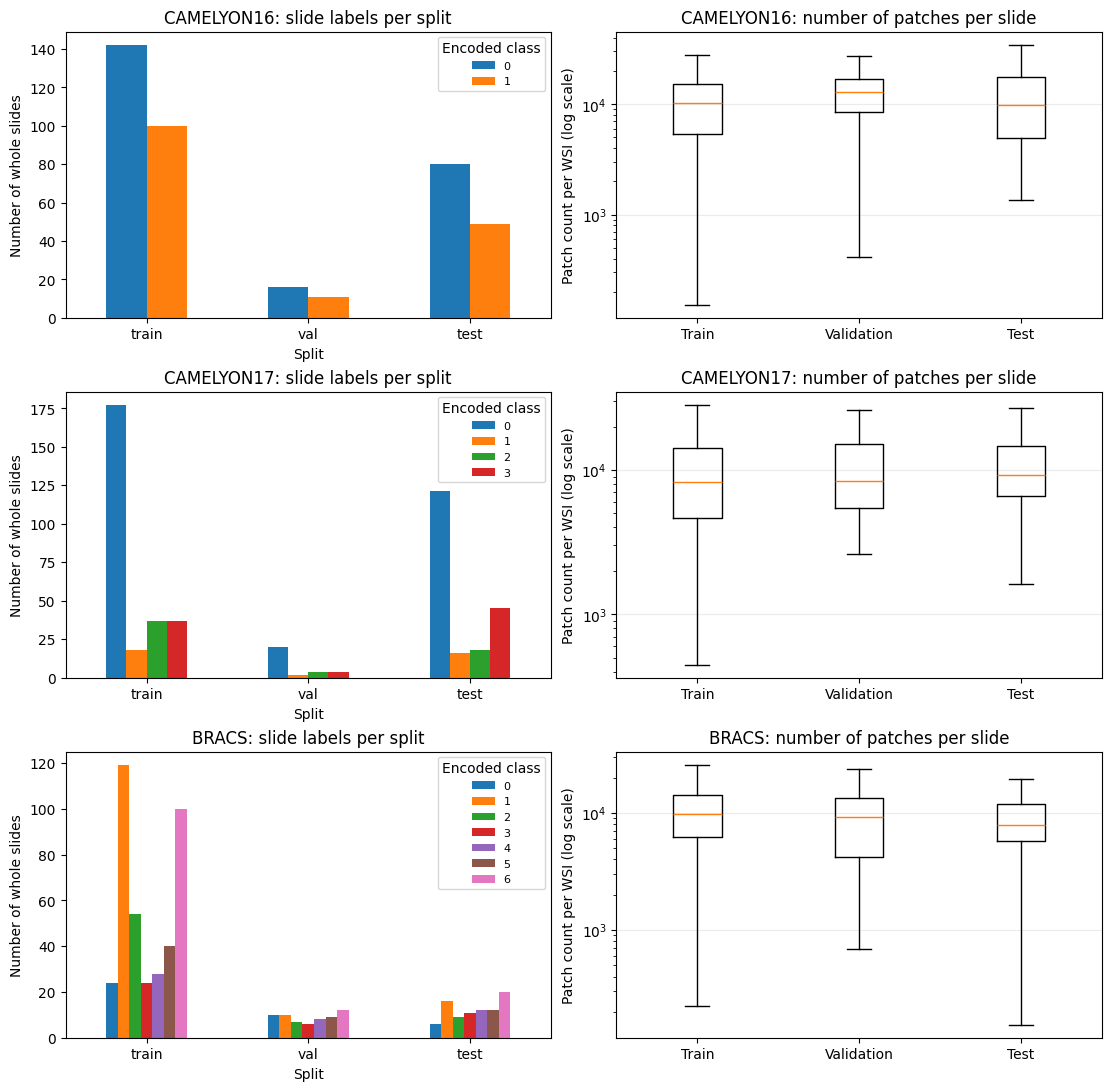

In [10]:
### ANESTIS CELL

# ADDITIONAL CELL B — directly after ADDITIONAL CELL A
# Figure: label distribution by split and varying number of patches per WSI.
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

unique_datasets = list(dataset_inventory['dataset'].unique())
fig, axes = plt.subplots(len(unique_datasets), 2,
                         figsize=(11, 3.6*len(unique_datasets)), squeeze=False,
                         constrained_layout=True)
for i, dataset_name in enumerate(unique_datasets):
    d = dataset_inventory.query('dataset == @dataset_name')
    count_table = pd.crosstab(d['split'], d['label']).reindex(
        index=['train', 'val', 'test'], fill_value=0)
    count_table.plot(kind='bar', ax=axes[i,0], rot=0, legend=True)
    axes[i,0].set_title(f'{dataset_name}: slide labels per split')
    axes[i,0].set_ylabel('Number of whole slides')
    axes[i,0].set_xlabel('Split')
    axes[i,0].legend(title='Encoded class', fontsize=8)
    box_data = [d.loc[d.split == name, 'patches'].to_numpy()
                for name in ['train','val','test']]
    axes[i,1].boxplot(box_data, showfliers=False)
    axes[i,1].set_xticklabels(['Train','Validation','Test'])
    axes[i,1].set_yscale('log')
    axes[i,1].set_title(f'{dataset_name}: number of patches per slide')
    axes[i,1].set_ylabel('Patch count per WSI (log scale)')
    axes[i,1].grid(axis='y', alpha=.25)
fig.savefig(report_dir / 'dataset_overview.png', dpi=300, bbox_inches='tight')
fig.savefig(report_dir / 'dataset_overview.pdf', bbox_inches='tight')
plt.show()


CAMELYON16: sample=1,600 patches, D=384, L2 norm median=42.852, near-constant dimensions (std < 1e-6)=0
CAMELYON17: sample=1,600 patches, D=384, L2 norm median=42.957, near-constant dimensions (std < 1e-6)=0
BRACS: sample=1,600 patches, D=384, L2 norm median=43.335, near-constant dimensions (std < 1e-6)=0


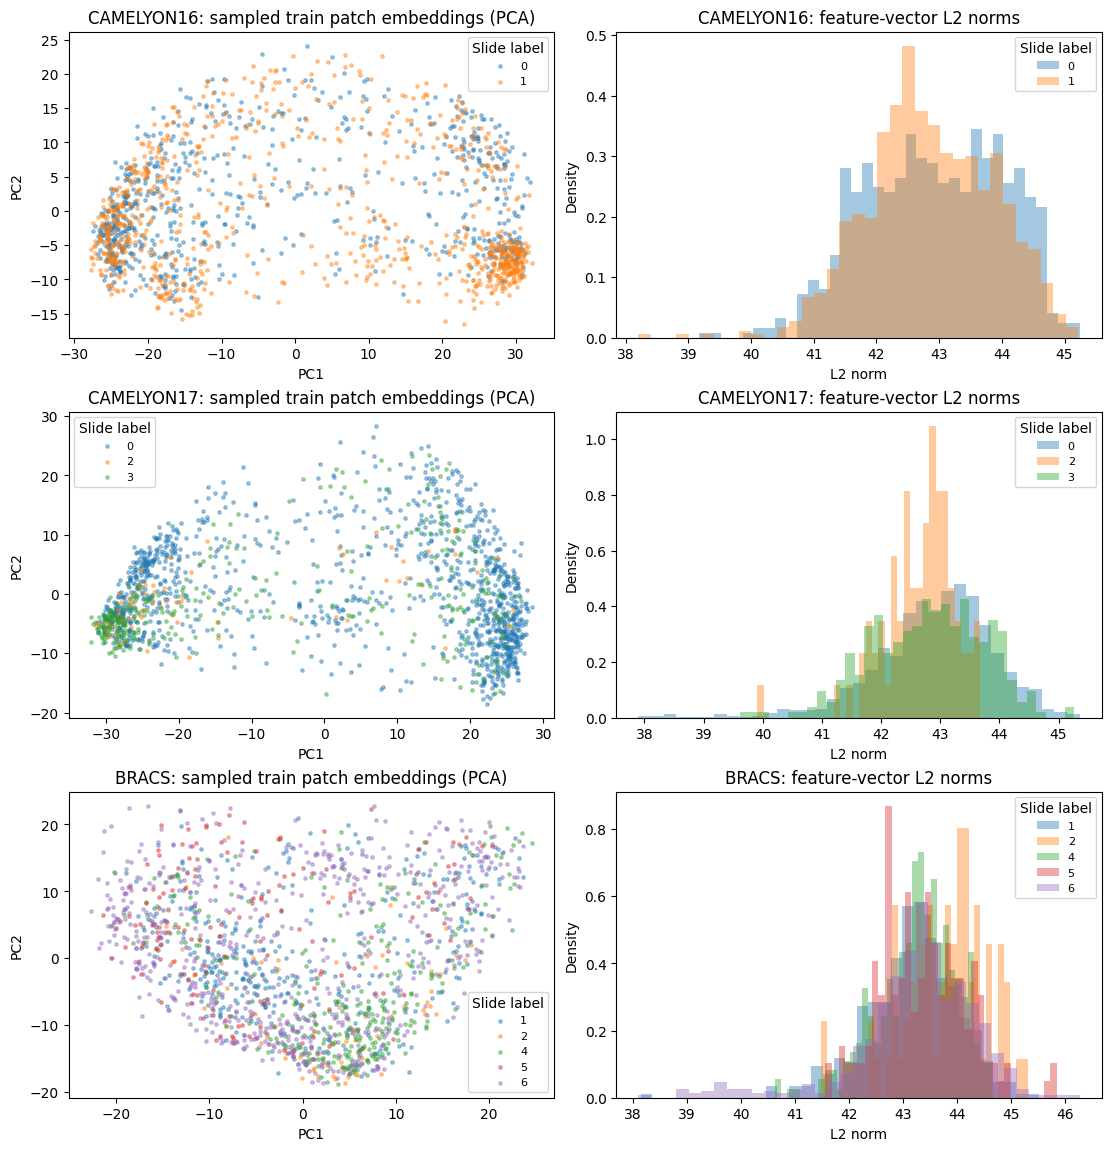

In [11]:
### ANESTIS CELL

# ADDITIONAL CELL C — after ADDITIONAL CELL B
# Sampling-only feature diagnostics. Do NOT assume dimensions have clinical meanings.
# Up to 20 slides and 80 random patches/slide/dataset: avoids full-HDF5 loading.
from sklearn.decomposition import PCA
rng = np.random.default_rng(42)
feature_records = []
fig, axes = plt.subplots(len(unique_datasets), 2,
                         figsize=(11, 3.8*len(unique_datasets)), squeeze=False,
                         constrained_layout=True)
for j, dataset_name in enumerate(unique_datasets):
    matching = dataset_inventory[dataset_inventory.dataset == dataset_name]
    # Prefer the training split for EDA to avoid repeatedly exploring held-out data.
    matching = matching[matching.split == 'train']
    picked = matching.sample(n=min(20, len(matching)), random_state=42)
    key = {v:k for k,v in config_labels.items()}[dataset_name]
    cfg = load_config(str(project_root / 'config' / CONFIG_FILES[key]))
    path = Path(cfg.data_dir)
    if not path.is_absolute(): path = project_root / path
    vectors, labels = [], []
    with h5py.File(path, 'r') as h5:
        for r in picked.itertuples():
            ds = h5[r.slide_id]['feat']
            n = ds.shape[0]
            idx = np.sort(rng.choice(n, size=min(80, n), replace=False))
            x = np.asarray(ds[idx], dtype=np.float32)
            finite = np.isfinite(x).all(axis=1)
            feature_records.append({'dataset':dataset_name, 'slide_id':r.slide_id,
                                    'sampled_patches':len(idx),
                                    'nonfinite_feature_rows':int((~finite).sum())})
            if finite.any():
                vectors.append(x[finite]); labels.extend([r.label]*int(finite.sum()))
    X = np.concatenate(vectors, axis=0)
    y = np.asarray(labels)
    norms = np.linalg.norm(X, axis=1)
    dims_sd = X.std(axis=0)
    projected = PCA(n_components=2, random_state=42).fit_transform(X)
    for lab in np.unique(y):
        mask = y == lab
        axes[j,0].scatter(projected[mask,0], projected[mask,1],
                          s=6, alpha=.4, label=str(lab), rasterized=True)
        axes[j,1].hist(norms[mask], bins=35, alpha=.4, label=str(lab), density=True)
    axes[j,0].set(title=f'{dataset_name}: sampled train patch embeddings (PCA)',
                  xlabel='PC1', ylabel='PC2')
    axes[j,1].set(title=f'{dataset_name}: feature-vector L2 norms',
                  xlabel='L2 norm', ylabel='Density')
    axes[j,0].legend(title='Slide label', fontsize=8)
    axes[j,1].legend(title='Slide label', fontsize=8)
    print(f'{dataset_name}: sample={len(X):,} patches, D={X.shape[1]}, '
          f'L2 norm median={np.median(norms):.3f}, '
          f'near-constant dimensions (std < 1e-6)={(dims_sd < 1e-6).sum()}')
fig.savefig(report_dir / 'feature_diagnostics.png', dpi=300, bbox_inches='tight')
fig.savefig(report_dir / 'feature_diagnostics.pdf', bbox_inches='tight')
plt.show()
pd.DataFrame(feature_records).to_csv(report_dir / 'sampled_feature_quality.csv', index=False)


**Questions for your report:**

- What is the difference between a `Dataset` and a `DataLoader`?
- Which Dataloader should use `shuffle=True`? Why?
- For a batch with input shape `[B, N, D]`, what do `B`, `N`, and `D` mean in this project?


# Step 2 - Implement the ABMIL model

For each patch feature $h_i$, the gated attention score follows Ilse et al. (2018):

$$
a_i = w^T\left[\tanh(Vh_i) \odot \sigma(Uh_i)\right].
$$

The attention logits are normalized over instances:

$$
\alpha_i = \frac{\exp(a_i)}{\sum_j \exp(a_j)},
$$

and the slide representation is

$$
z = \sum_i \alpha_i h_i.
$$

You will implement the learnable layers and the key `forward()` operations.

[Custom nn Modules](https://docs.pytorch.org/tutorials/beginner/examples_nn/polynomial_module.html)

[nn.Linear](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Linear.html)

[nn.modules.dropout](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Dropout.html)

[nn.ReLU](https://docs.pytorch.org/docs/2.14/generated/torch.nn.ReLU.html)

[torch.nn.functional.softmax (F.softmax)](https://docs.pytorch.org/docs/2.14/generated/torch.nn.functional.softmax.html)

[torch.bmm](https://docs.pytorch.org/docs/2.14/generated/torch.bmm.html)

In [12]:
class Classifier1FC(nn.Module):
    def __init__(self, n_channels, n_classes, droprate=0.0):
        super().__init__()
        self.dropout = nn.Dropout(droprate) if droprate > 0 else nn.Identity()
        # TODO 2A: one linear layer from n_channels to n_classes.
        self.fc = nn.Linear(in_features = n_channels, out_features = n_classes) # TODO('Create a linear classifier')

    def forward(self, x):
        # TODO 2B: apply dropout, then the classifier.
        return self.fc(self.dropout(x)) # TODO('Return classifier output')


class DimReduction(nn.Module):
    def __init__(self, n_channels, m_dim):
        super().__init__()
        # TODO 2C: project patch features to m_dim and use ReLU.
        self.fc = nn.Linear(in_features = n_channels, out_features = m_dim) # TODO('Create Linear layer')
        self.relu = nn.ReLU() # TODO('Create ReLU')

    def forward(self, x):
        # TODO 2D: linear projection followed by ReLU.
        return self.relu(self.fc(x)) # TODO('Return ReLU(linear(x))')


class AttentionGated(nn.Module):
    def __init__(self, L=256, D=128, K=1):
        super().__init__()
        self.attention_V = nn.Sequential(nn.Linear(L, D), nn.Tanh())
        self.attention_U = nn.Sequential(nn.Linear(L, D), nn.Sigmoid())
        self.attention_weights_w = nn.Linear(D, K)

    def forward(self, x):
        # x: [B, N, L]
        # TODO 2E: implement the two gated branches.
        a_v = self.attention_V(x) # TODO('Compute tanh branch')
        a_u = self.attention_U(x) # TODO('Compute sigmoid branch')

        a = self.attention_weights_w(a_v * a_u)
        return a.transpose(1, 2)             


class ABMIL(nn.Module):
    def __init__(self, conf):
        super().__init__()
        self.dimreduction = DimReduction(conf.D_feat, conf.D_inner)
        self.attention = AttentionGated(conf.D_inner, conf.D_attn, K=1)
        self.classifier = Classifier1FC(conf.D_inner, conf.n_class, conf.droprate)

    def forward(self, x, return_attention=False):
        # x: [B, N, D_feat]
        med_feat = self.dimreduction(x)       # [B, N, D_inner]
        a_logits = self.attention(med_feat)   # [B, 1, N]


        # TODO 2G: normalize attention logits over the instance dimension.
        attention = F.softmax(input = a_logits, dim = -1) # TODO('Apply softmax over patches')
        
        # TODO 2H: weighted aggregation. torch.bmm is useful here.
        bag_feat = torch.bmm(input = attention, mat2 = med_feat) # [B, 1, D_inner] # TODO('Aggregate patch features into one slide representation')
        bag_feat = bag_feat.squeeze(1) # # [B, D_inner]

        # TODO 2I: classify the slide representation.
        logits = self.classifier(bag_feat) # [B, n_class] # TODO('Compute slide-level logits')

        if return_attention:
            return logits, attention
        return logits


**Sanity Check**

Before running the full training pipeline, check the tensor shapes and attention normalization.


In [13]:
model_cpu = ABMIL(conf).eval()

x_demo = torch.randn(2, 7, conf.D_feat)


with torch.no_grad():
    logits_demo, attn_demo = model_cpu(x_demo, return_attention=True)

print('logits:', logits_demo.shape)
print('attention:', attn_demo.shape)
print('attention sums:', attn_demo.sum(dim=-1))

assert logits_demo.shape == (2, int(conf.n_class))
assert attn_demo.shape == (2, 1, 7)
torch.testing.assert_close(attn_demo.sum(dim=-1), torch.ones(2, 1))
print('Sanity check passed.')


logits: torch.Size([2, 2])
attention: torch.Size([2, 1, 7])
attention sums: tensor([[1.],
        [1.]])
Sanity check passed.


**Questions:**

- Which tensors in your model contain trainable parameters?
- What properties do attention weights have after softmax?
- Could we replace softmax with another function?


# Step 3 - Device, loss, and optimizer

For multi-class slide classification, use cross-entropy as the baseline objective and AdamW as the baseline optimizer. Complete the code below.

[nn.CrossEntropyLoss](https://docs.pytorch.org/docs/2.14/generated/torch.nn.CrossEntropyLoss.html)

[torch.optim.AdamW](https://docs.pytorch.org/docs/2.14/generated/torch.optim.AdamW.html)

In [14]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ABMIL(conf).to(device)

# TODO 3A: define the multi-class classification loss.
criterion = nn.CrossEntropyLoss() # TODO('Create nn.CrossEntropyLoss()')

# TODO 3B: create AdamW and pass the model parameters, learning rate, and weight decay.
optimizer = torch.optim.AdamW(model.parameters(), lr = conf.lr, weight_decay = conf.wd) # TODO('Create torch.optim.AdamW(...)')

print('Device:', device)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))


Device: cuda
Trainable parameters: 164995


# Step 4 - Complete one training epoch

The essential PyTorch optimization sequence is:

`model.train()` -> move tensors to device -> `zero_grad()` -> forward pass -> compute loss -> `backward()` -> `step()`.

Implement this sequence yourself. This is one of the main learning objectives of the project.

[Training with PyTorch](https://docs.pytorch.org/tutorials/beginner/introyt/trainingyt.html)

[train() vs eval()](https://discuss.pytorch.org/t/model-train-and-model-eval-vs-model-and-model-eval/5744)

In [15]:
def train_one_epoch(model, criterion, data_loader, optimizer, device):
    # TODO 4A: put the model in training mode.
    model.train() # TODO('Call model.train()')

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for data in data_loader:
        # TODO 4B: move input and labels to the selected device.
        bag    = data["input"].to(device=device, dtype=torch.float32) # TODO('Move data["input"] to device as float32')
        labels = data["label"].to(device=device, dtype=torch.long)    # TODO('Move data["label"] to device as long')

        # TODO 4C: clear gradients from the previous iteration.
        optimizer.zero_grad() # TODO('optimizer zero grad')

        # TODO 4D: forward pass.
        logits = model(bag) # TODO('Pass the feature bag to the ABMIL')

        # TODO 4E: compute the loss.
        loss = criterion(logits, labels) # TODO('criterion(logits, labels)')

        # TODO 4F: back-propagate gradients.
        loss.backward() # TODO('loss.backward()')

        # TODO 4G: update the model parameters.
        optimizer.step() # TODO('optimizer.step()')

        batch_size = labels.shape[0]
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += batch_size

    return {
        'loss': total_loss / total_examples,
        'acc': 100.0 * total_correct / total_examples,
    }


# Step 5 - Validation and test evaluation

Evaluation should not update the model. Complete the missing lines and use the provided metric helper for macro-AUROC and macro-F1.


In [16]:
@torch.no_grad()
def evaluate(model, criterion, data_loader, device, conf):
    # TODO 5A: switch to evaluation mode.
    model.eval() # TODO('Call model.eval()')

    total_loss = 0.0
    total_examples = 0
    probabilities_all = []
    labels_all = []

    for data in data_loader:
        # TODO 5B: move data to device.
        bag = data["input"].to(device=device, dtype=torch.float32) # TODO('Move input to device')
        labels = data["label"].to(device=device, dtype=torch.long) # TODO('Move labels to device')

        # TODO 5C: forward pass and loss.
        logits = model(bag) # TODO('Compute logits')
        loss = criterion(logits, labels) # TODO('Compute loss')

        # TODO 5D: convert class logits into probabilities.
        probabilities = F.softmax(logits, dim=1) # TODO('Apply softmax over classes')

        total_loss += loss.item() * labels.shape[0]
        total_examples += labels.shape[0]
        probabilities_all.append(probabilities)
        labels_all.append(labels)

    probabilities_all = torch.cat(probabilities_all, dim=0)
    labels_all = torch.cat(labels_all, dim=0)
    metrics = classification_metrics(probabilities_all, labels_all, conf.n_class)
    metrics['loss'] = total_loss / total_examples
    return metrics


**Checkpoint questions:**

- Why are `model.eval()` and `torch.no_grad()` different concepts?
- What would happen if gradients were accumulated because `optimizer.zero_grad()` was omitted?
- Why must the test set not be used to choose the best epoch?


# Step 6 - Train, validate, and select the best checkpoint

Use the validation set to choose the best epoch. The test set must remain untouched until model selection is complete.

For debugging, set `NUM_EPOCHS = 2`. For your reported baseline, use the full configured epoch count unless instructed otherwise.


In [17]:
NUM_EPOCHS = int(conf.train_epoch)  # You may temporarily set this to 2 while debugging.

best_score = float('-inf')
best_epoch = -1
best_model_state = None
history = []

for epoch in range(NUM_EPOCHS):
    start = time.time()
    train_metrics = train_one_epoch(model, criterion, train_loader, optimizer, device)
    val_metrics = evaluate(model, criterion, val_loader, device, conf)

    # Baseline selection criterion: macro-AUROC + macro-F1.
    score = val_metrics['auc'] + val_metrics['f1']

    if score > best_score:
        best_score = score
        best_epoch = epoch
        best_model_state = copy.deepcopy(model.state_dict())
    row = {
        'epoch': epoch,
        'train_loss': train_metrics['loss'],
        'train_acc': train_metrics['acc'],
        'val_loss': val_metrics['loss'],
        'val_acc': val_metrics['acc'],
        'val_auc': val_metrics['auc'],
        'val_f1': val_metrics['f1'],
    }
    history.append(row)
    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
          f"train loss={row['train_loss']:.4f} acc={row['train_acc']:.2f} | "
          f"val loss={row['val_loss']:.4f} auc={row['val_auc']:.3f} f1={row['val_f1']:.3f} | "
          f"best={best_epoch+1} | {time.time()-start:.1f}s")

assert best_model_state is not None


Epoch 01/30 | train loss=0.6759 acc=57.85 | val loss=0.5061 auc=0.892 f1=0.785 | best=1 | 11.4s
Epoch 02/30 | train loss=0.4500 acc=78.51 | val loss=0.1814 auc=1.000 f1=1.000 | best=2 | 7.7s
Epoch 03/30 | train loss=0.2325 acc=91.74 | val loss=0.0932 auc=1.000 f1=1.000 | best=2 | 7.7s
Epoch 04/30 | train loss=0.1601 acc=95.45 | val loss=0.0197 auc=1.000 f1=1.000 | best=2 | 6.1s
Epoch 05/30 | train loss=0.1306 acc=95.87 | val loss=0.0101 auc=1.000 f1=1.000 | best=2 | 5.5s
Epoch 06/30 | train loss=0.1053 acc=96.28 | val loss=0.0111 auc=1.000 f1=1.000 | best=2 | 5.5s
Epoch 07/30 | train loss=0.0849 acc=97.11 | val loss=0.0113 auc=1.000 f1=1.000 | best=2 | 5.6s
Epoch 08/30 | train loss=0.0537 acc=98.35 | val loss=0.0046 auc=1.000 f1=1.000 | best=2 | 5.6s
Epoch 09/30 | train loss=0.0436 acc=98.76 | val loss=0.0026 auc=1.000 f1=1.000 | best=2 | 5.8s
Epoch 10/30 | train loss=0.0451 acc=98.35 | val loss=0.0019 auc=1.000 f1=1.000 | best=2 | 5.5s
Epoch 11/30 | train loss=0.0221 acc=99.17 | val l

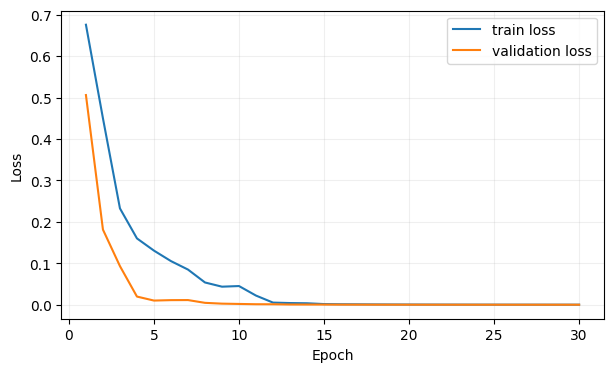

In [18]:
# Plot learning curves.
epochs = [x['epoch'] + 1 for x in history]
plt.figure(figsize=(7, 4))
plt.plot(epochs, [x['train_loss'] for x in history], label='train loss')
plt.plot(epochs, [x['val_loss'] for x in history], label='validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(alpha=0.2)
plt.show()


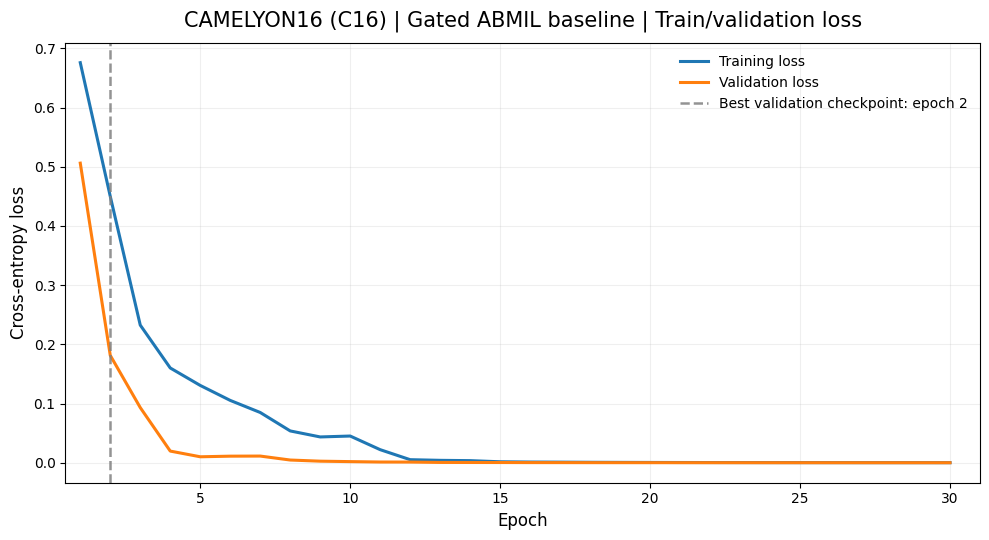

Dataset: CAMELYON16
Model: Gated ABMIL baseline
Selected epoch: 2
PNG saved to: C:\Users\anest\Desktop\UofT\Digital Image Processing\Project A\Project_A_Starter_Code\Project_A_Starter_Code\report_figures\C16_train_val_loss.png
PDF saved to: C:\Users\anest\Desktop\UofT\Digital Image Processing\Project A\Project_A_Starter_Code\Project_A_Starter_Code\report_figures\C16_train_val_loss.pdf


In [19]:

# ============================================================
# INDEPENDENT REPORT CELL: Training / Validation Loss
# Place AFTER Step 6 (training and validation)
# ============================================================

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# 1. Output directory
fig_dir = Path(PROJECT_DIR).resolve() / "report_figures"
fig_dir.mkdir(parents=True, exist_ok=True)

# 2. Dataset and model information
run_name = str(DATASET).upper()

dataset_title = {
    "C16": "CAMELYON16",
    "C17": "CAMELYON17",
    "BRACS": "BRACS"
}.get(run_name, run_name)

model_title = "Gated ABMIL baseline"

# 3. Convert training history to DataFrame
hist = pd.DataFrame(history)

assert not hist.empty, "Training history is empty."
assert all(
    col in hist.columns
    for col in ["epoch", "train_loss", "val_loss"]
), "Required loss columns are missing."

# Epoch numbers in your notebook start at 0
epochs = hist["epoch"].to_numpy() + 1
selected_epoch = best_epoch + 1

# 4. Plot train and validation loss
fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(
    epochs,
    hist["train_loss"],
    label="Training loss",
    linewidth=2.2,
    color="tab:blue"
)

ax.plot(
    epochs,
    hist["val_loss"],
    label="Validation loss",
    linewidth=2.2,
    color="tab:orange"
)

# Mark the selected validation checkpoint
ax.axvline(
    x=selected_epoch,
    color="gray",
    linestyle="--",
    linewidth=1.8,
    alpha=0.85,
    label=f"Best validation checkpoint: epoch {selected_epoch}"
)

# 5. Axis labels and title
ax.set_title(
    f"{dataset_title} ({run_name}) | "
    f"{model_title} | Train/validation loss",
    fontsize=15,
    pad=12
)

ax.set_xlabel("Epoch", fontsize=12)
ax.set_ylabel("Cross-entropy loss", fontsize=12)

ax.set_xlim(0.5, max(epochs) + 1)

ax.grid(
    True,
    alpha=0.20,
    linestyle="-"
)

ax.legend(
    loc="upper right",
    frameon=False,
    fontsize=10
)

fig.tight_layout()

# 6. Save high-resolution figures
png_path = fig_dir / f"{run_name}_train_val_loss.png"
pdf_path = fig_dir / f"{run_name}_train_val_loss.pdf"

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight"
)

plt.show()

# 7. Save numerical history as well
hist.to_csv(
    fig_dir / f"{run_name}_training_history.csv",
    index=False
)

print("Dataset:", dataset_title)
print("Model:", model_title)
print("Selected epoch:", selected_epoch)
print("PNG saved to:", png_path)
print("PDF saved to:", pdf_path)


# Step 7 - Final held-out test evaluation

Only now, after the best checkpoint has been chosen from validation performance, load it and evaluate once on the test set.


In [20]:
model.load_state_dict(best_model_state)
test_metrics = evaluate(model, criterion, test_loader, device, conf)

print('Best validation epoch:', best_epoch + 1)
print('Final test metrics:')
for key, value in test_metrics.items():
    print(f'  {key}: {value:.4f}')


Best validation epoch: 2
Final test metrics:
  auc: 0.8704
  acc: 82.9457
  f1: 0.8159
  loss: 0.4165


              precision    recall  f1-score   support

     Class 0      0.845     0.887     0.866        80
     Class 1      0.800     0.735     0.766        49

    accuracy                          0.829       129
   macro avg      0.823     0.811     0.816       129
weighted avg      0.828     0.829     0.828       129



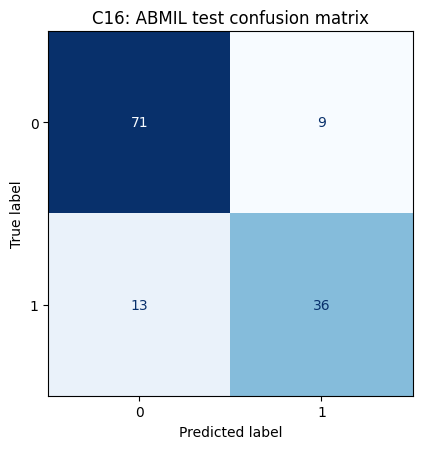

This does NOT use the held-out test set for model selection.


In [21]:
### ANESTIS


# INDEPENDENT OPTIONAL REPORT CELL: insert after Step 7's held-out test evaluation.
# Descriptive only: NEVER use test confusion/ROC outcomes to choose a model or epoch.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

fig_dir = Path(PROJECT_DIR).resolve() / 'report_figures'
fig_dir.mkdir(parents=True, exist_ok=True)
model.load_state_dict(best_model_state)
model.eval()
ys, probs = [], []
with torch.no_grad():
    for batch in test_loader:
        logits = model(batch['input'].to(device, dtype=torch.float32))
        ys.append(batch['label'].cpu().numpy())
        probs.append(torch.softmax(logits, dim=1).cpu().numpy())
y_true = np.concatenate(ys)
y_prob = np.concatenate(probs)
y_pred = y_prob.argmax(axis=1)
class_ids = list(range(int(conf.n_class)))
cm = confusion_matrix(y_true, y_pred, labels=class_ids)
print(classification_report(y_true, y_pred, labels=class_ids,
                            target_names=[f'Class {i}' for i in class_ids],
                            zero_division=0, digits=3))
fig, ax = plt.subplots(figsize=(5.0, 4.6))
ConfusionMatrixDisplay(cm, display_labels=[str(i) for i in class_ids]).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d')
ax.set_title(f'{DATASET}: ABMIL test confusion matrix')
fig.tight_layout()
fig.savefig(fig_dir / f'{DATASET}_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()
pd.DataFrame({'true_label': y_true, 'predicted_label': y_pred,
              **{f'prob_{k}': y_prob[:,k] for k in class_ids}}).to_csv(
    fig_dir / f'{DATASET}_test_predictions.csv', index=False)
print('This does NOT use the held-out test set for model selection.')


              precision    recall  f1-score   support

     Class 0      0.845     0.887     0.866        80
     Class 1      0.800     0.735     0.766        49

    accuracy                          0.829       129
   macro avg      0.823     0.811     0.816       129
weighted avg      0.828     0.829     0.828       129



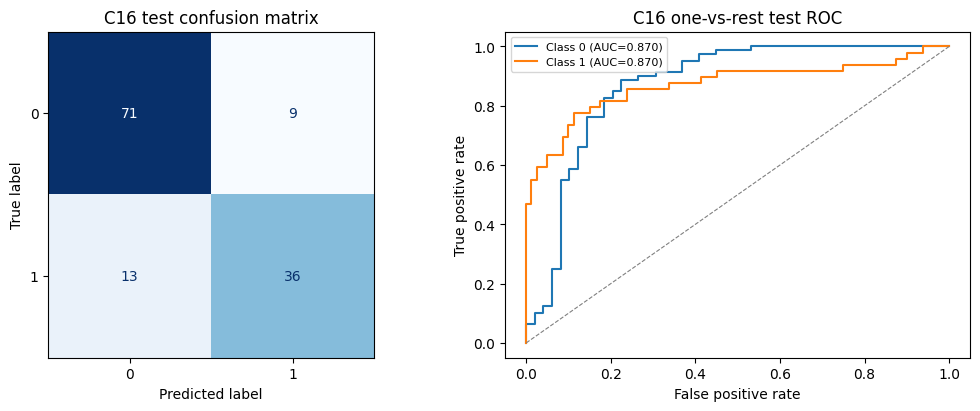

In [22]:
### ANESTIS

# ADDITIONAL CELL D — after Step 7 / final held-out test (original cell 30)
# Only descriptive test evaluation; DO NOT use these results for model selection.
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_curve, auc
import numpy as np

model.eval()
y_true, y_prob = [], []
with torch.no_grad():
    for batch in test_loader:
        logits = model(batch['input'].to(device, dtype=torch.float32))
        y_prob.append(torch.softmax(logits, dim=1).cpu().numpy())
        y_true.append(batch['label'].numpy())
y_true = np.concatenate(y_true)
y_prob = np.concatenate(y_prob)
y_pred = y_prob.argmax(axis=1)
class_ids = list(range(int(conf.n_class)))
print(classification_report(y_true, y_pred, labels=class_ids,
                            target_names=[f'Class {k}' for k in class_ids],
                            zero_division=0, digits=3))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=class_ids,
                                         ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'{DATASET} test confusion matrix')
for k in class_ids:
    binary = (y_true == k).astype(int)
    if len(np.unique(binary)) < 2:
        print(f'Class {k}: one-vs-rest ROC undefined (missing positive/negative).')
        continue
    fpr, tpr, _ = roc_curve(binary, y_prob[:,k])
    axes[1].plot(fpr, tpr, label=f'Class {k} (AUC={auc(fpr,tpr):.3f})')
axes[1].plot([0,1], [0,1], '--', color='gray', linewidth=.8)
axes[1].set(xlabel='False positive rate', ylabel='True positive rate',
            title=f'{DATASET} one-vs-rest test ROC')
axes[1].legend(fontsize=8)
fig.savefig(report_dir / f'{DATASET}_test_diagnostics.png', dpi=300,
            bbox_inches='tight')
fig.savefig(report_dir / f'{DATASET}_test_diagnostics.pdf', bbox_inches='tight')
plt.show()

# Step 8 -  Inspect Attention on One Slide

Attention is useful for understanding which instances contribute strongly to the learned bag representation, but attention weights should not automatically be interpreted as causal explanations.


In [23]:
one_batch = mil_collate_fn([test_data[0]])
model.eval()
with torch.no_grad():
    logits, attention = model(
        one_batch['input'].to(device, dtype=torch.float32),
        return_attention=True,
    )

print('Slide:', one_batch['slide_id'][0])
print('Predicted class:', int(logits.argmax(dim=1)[0]))
print('Attention shape:', tuple(attention.shape))
print('Attention sum for first slide:', float(attention[0].sum()))


Slide: test_001
Predicted class: 1
Attention shape: (1, 1, 17294)
Attention sum for first slide: 1.0


## Visualize Attention on Whole-Slide Images (WSIs)

Before running the attention visualization, please complete the following steps:

1. Visit the [ECE1512-WSI-Feature dataset on Hugging Face](https://huggingface.co/datasets/LeonYe/ECE1512-WSI-Feature)

2. Download the original WSIs `test_067.tif` and `test_068.tif` and the corresponding tumor annotation file `test_068.xml`.

3. Create a folder named `slide/` under your project directory and place the downloaded files in this folder.

Run this cell after training and final test evaluation, with `DATASET = 'C16'`. It restores `best_model_state` and plots the two slides in `PROJECT_DIR/slide`:

- **test_068 (tumor):** attention overlay and green contours from `test_068.xml`, including a zoom of the annotated region.
- **test_067 (normal):** attention overlay without annotation contours, including a zoom around the highest-attention patch.

The blue rectangle marks the zoom shown on the right. Colors show **attention percentiles within each slide**, not patch tumor probabilities; areas without extracted patches stay transparent. The displayed `P(tumor)` is the model's slide-level prediction.

HDF5 patch coordinates and XML contour coordinates are assumed to be expressed in level-0 `(x, y)`  coordinates; patch coordinates are treated as top-left corners. The function parameter `patch_size_level0=512` is an editable **assumption** for the patch footprint because these HDF5 files do not store patch-size metadata. Match it to the feature extractor's patch size for an exact footprint. All visualization functions are in `wsi_visualization.py`; the cell below only calls `visualize_wsi_attention`.

[OpenSlide Python](https://openslide.org/api/python/) reads a thumbnail and a pyramid-level crop rather than loading the full-resolution WSI into memory. If dependencies are missing, run `%pip install openslide-python openslide-bin` and restart the kernel if needed. Raw per-patch attention and coordinates are retained in `attention_visualizations`.


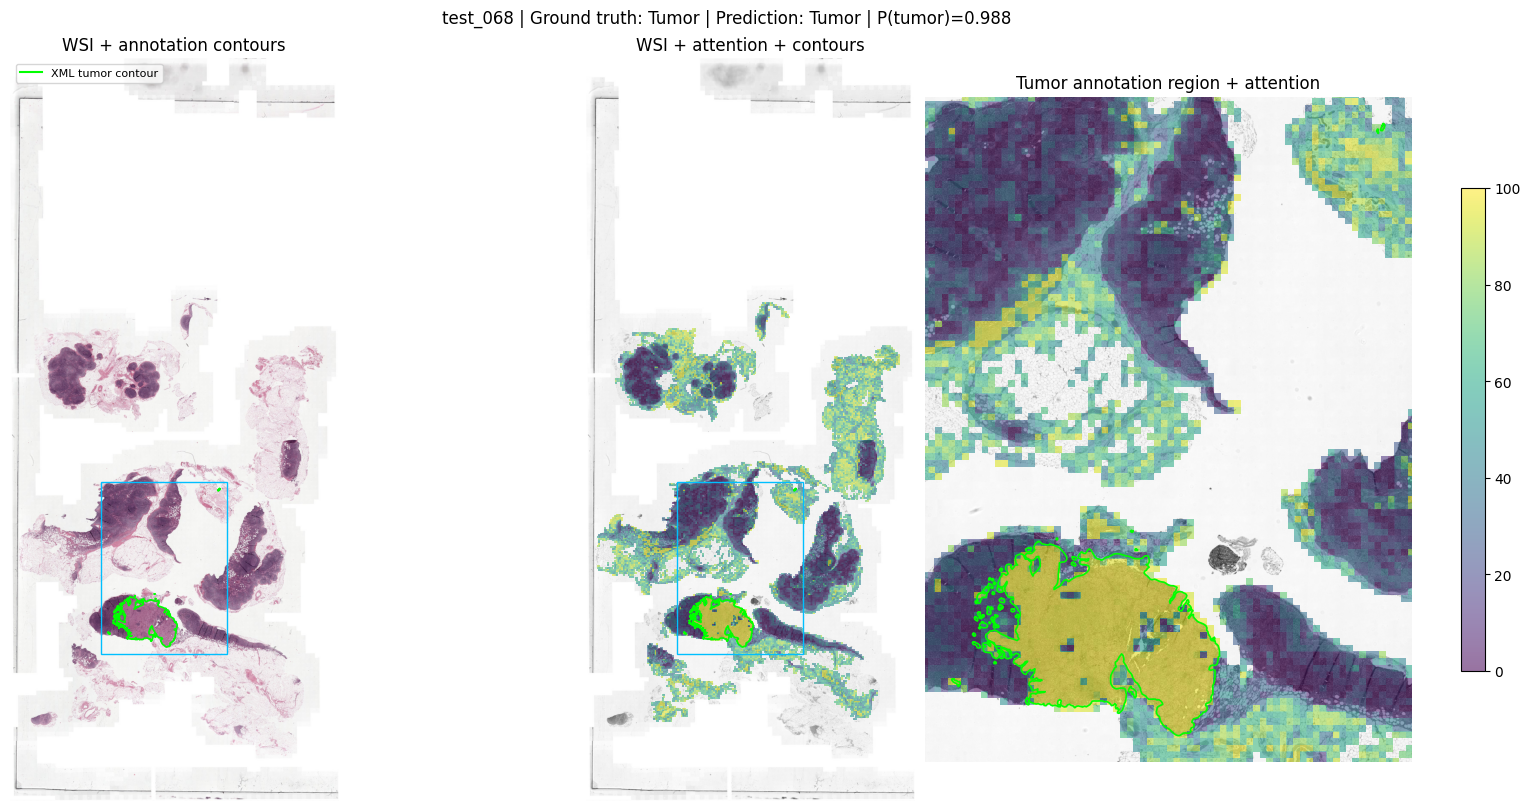

test_068: 15,037 patches; attention sum=1.000000; 45 annotation contours


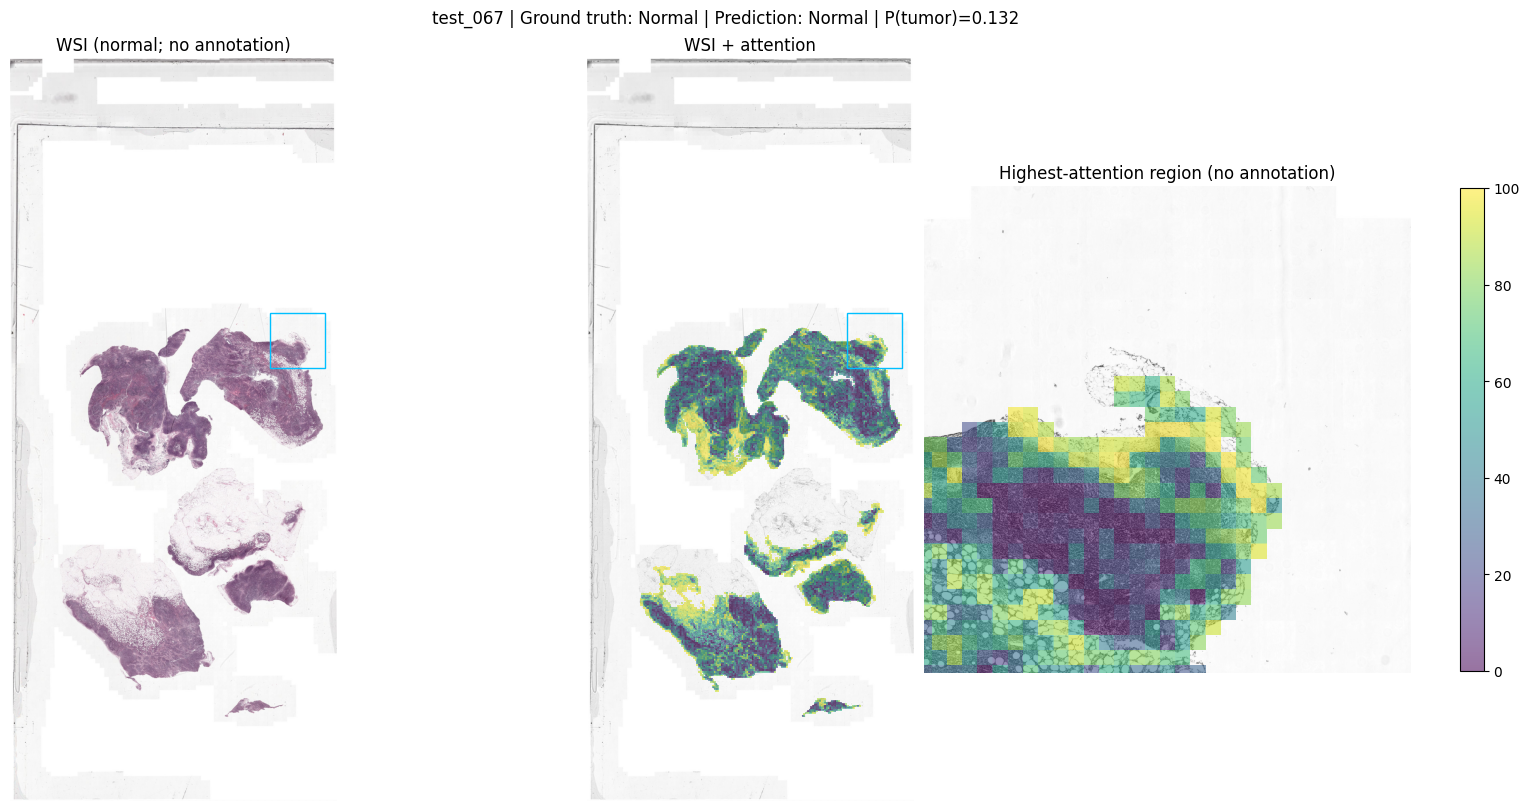

test_067: 11,926 patches; attention sum=1.000000; 0 annotation contours (no XML available)


In [26]:
if DATASET == 'C16':
    attention_visualizations = visualize_wsi_attention(model, conf, PROJECT_DIR, best_model_state)


# Step 9 - Research extension: propose two ideas, implement one of them

After completing the ABMIL baseline, propose **two distinct research ideas**. Select **one** for implementation and evaluation on **CAMELYON16 (C16), CAMELYON17 (C17), and BRACS**. You may explore explainability, more advanced model structures, improved objectives beyond cross-entropy, or another well-motivated direction.

**A negative result will not be penalized if the design choices, experiments, observations, and possible reasons for failure are well justified.** Report evidence relevant to your hypothesis: an explainability idea, for example, needs an explanation evaluation in addition to classification results.

Feel free to contact your TA to discuss your research ideas.

In [27]:
### ANESTIS


# ADDED SHARED REPORTING/EXPORT HELPERS (does NOT change A0 or extension predictions)
import json, gc, warnings
import numpy as np
import pandas as pd
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, f1_score, recall_score)

RESULTS_ROOT = Path(PROJECT_DIR).resolve()
CLASS_IDS = list(range(int(conf.n_class)))

def to_python(x):
    if isinstance(x, dict): return {str(k): to_python(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)): return [to_python(v) for v in x]
    if isinstance(x, (np.integer,)): return int(x)
    if isinstance(x, (np.floating,)): return float(x) if np.isfinite(x) else None
    if isinstance(x, torch.Tensor): return to_python(x.detach().cpu().numpy().tolist())
    if isinstance(x, (float,)): return x if np.isfinite(x) else None
    return x

def stage_dir(stage):
    d = RESULTS_ROOT / f'results_{DATASET}_{stage}'  # EXACT requested naming convention
    d.mkdir(parents=True, exist_ok=True)
    return d

def train_label_counts():
    # ADDED A1: ONLY training slide labels, never validation/test labels.
    # Fast metadata-only path for the original course HDF5 format.
    counts = np.zeros(int(conf.n_class), dtype=np.int64)
    try:
        import h5py
        from dataloader import _map_label
        with h5py.File(conf.data_dir, 'r') as handle:
            for sid in train_data.data_names:
                raw = int(handle[sid].attrs['label'])
                y = int(_map_label(raw, conf.dataset, int(conf.n_class)))
                counts[y] += 1
    except (ImportError, AttributeError, KeyError, OSError, TypeError) as exc:
        # Fallback works with other course-style Dataset implementations.
        print('Using train_data label fallback:', type(exc).__name__)
        counts[:] = 0
        for j in range(len(train_data)):
            label = train_data[j]['label']
            counts[int(torch.as_tensor(label).item())] += 1
    if not np.all(counts > 0):
        raise ValueError(f'Expected at least one training slide per class, got {counts}')
    return counts

TRAIN_COUNTS = train_label_counts()
print('Train-slide class counts:', TRAIN_COUNTS.tolist())

def collect_stage_predictions(model, loader, include_attention=False):
    # ADDED: same forward logits as A0; NEVER applies adjusted logits at test time.
    model.eval()
    ys, probs, ids = [], [], []
    first_attention = None
    first_slide = None
    with torch.no_grad():
        for batch in loader:
            x = batch['input'].to(device, dtype=torch.float32)
            y = batch['label'].to(device, dtype=torch.long).reshape(-1)
            if include_attention and first_attention is None:
                logits, attention = model(x, return_attention=True)
                first_attention = attention[0].detach().cpu().numpy()
                sid = batch.get('slide_id', ['unknown'])
                first_slide = str(sid[0] if isinstance(sid, (tuple, list)) else sid)
            else:
                logits = model(x)
            ys.append(y.cpu().numpy())
            probs.append(F.softmax(logits, dim=-1).cpu().numpy())
            sid = batch.get('slide_id', None)
            if isinstance(sid, (tuple, list)):
                ids.extend([str(v) for v in sid])
            elif sid is not None:
                ids.extend([str(sid)] * y.shape[0])
            else:
                ids.extend([f'row_{len(ids)+v}' for v in range(y.shape[0])])
    yy = np.concatenate(ys).astype(int)
    pp = np.concatenate(probs)
    return yy, pp, ids, first_attention, first_slide

def prediction_metrics(y, p):
    predicted = p.argmax(axis=1)
    per_auc = {}
    for c in CLASS_IDS:
        binary = (y == c).astype(int)
        per_auc[f'class_{c}'] = (float(roc_auc_score(binary, p[:, c]))
                                 if len(np.unique(binary)) == 2 else None)
    valid_auc = [z for z in per_auc.values() if z is not None]
    return {
        'accuracy': float(np.mean(y == predicted) * 100.0),
        'macro_f1': float(f1_score(y, predicted, labels=CLASS_IDS, average='macro', zero_division=0)),
        'macro_ovr_auc': float(np.mean(valid_auc)) if valid_auc else None,
        'per_class_auc': per_auc,
        'class_recall': {str(c): float(np.mean(predicted[y == c] == c)) if np.any(y == c) else None
                         for c in CLASS_IDS},
        'n_slides': int(len(y))
    }

def save_predictions(y, p, slide_ids, directory, split):
    pd.DataFrame({
        'slide_id': slide_ids, 'y_true': y, 'y_pred': p.argmax(axis=1),
        **{f'prob_{c}': p[:, c] for c in CLASS_IDS}
    }).to_csv(directory / f'{split}_predictions.csv', index=False)

def plot_stage_figures(stage, directory, hist, y, p, att, slide_id, best_ep):
    epochs = hist['epoch'].to_numpy() + 1
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    ax.plot(epochs, hist['train_loss'], label='Training objective')
    ax.plot(epochs, hist['val_loss'], label='Validation CE (raw logits)')
    ax.axvline(best_ep + 1, linestyle='--', color='gray', label=f'Best epoch {best_ep+1}')
    ax.set(xlabel='Epoch', ylabel='Loss', title=f'{DATASET} {stage}: learning curves')
    ax.legend(); ax.grid(alpha=.2); fig.tight_layout()
    fig.savefig(directory / 'learning_curves.png', dpi=180)
    plt.show(); plt.close(fig)

    yp = p.argmax(axis=1)
    cm = confusion_matrix(y, yp, labels=CLASS_IDS)
    pd.DataFrame(cm, index=CLASS_IDS, columns=CLASS_IDS).to_csv(directory / 'confusion_matrix.csv')
    fig, ax = plt.subplots(figsize=(5.6, 4.8))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_IDS).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{DATASET} {stage}: held-out test confusion matrix'); fig.tight_layout()
    fig.savefig(directory / 'confusion_matrix.png', dpi=180)
    plt.show(); plt.close(fig)

    fig, ax = plt.subplots(figsize=(6.2, 4.7))
    n_curves = 0
    for c in CLASS_IDS:
        binary = (y == c).astype(int)
        if len(np.unique(binary)) < 2: continue  # AUROC undefined when class absent.
        fpr, tpr, _ = roc_curve(binary, p[:, c])
        auc_val = roc_auc_score(binary, p[:, c]); n_curves += 1
        ax.plot(fpr, tpr, label=f'{c} (AUC={auc_val:.3f})')
    ax.plot([0,1], [0,1], '--', color='gray', linewidth=1)
    ax.set(xlabel='False-positive rate', ylabel='True-positive rate',
           title=f'{DATASET} {stage}: test one-vs-rest ROC')
    if n_curves: ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(directory / 'roc_curves.png', dpi=180)
    plt.show(); plt.close(fig)

    recalls = [float(np.mean(yp[y == c] == c)) if np.any(y == c) else np.nan for c in CLASS_IDS]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar([str(c) for c in CLASS_IDS], [0 if np.isnan(z) else z * 100 for z in recalls])
    ax.set(ylim=(0, 100), xlabel='Class', ylabel='Recall (%)',
           title=f'{DATASET} {stage}: held-out recall per class')
    fig.tight_layout(); fig.savefig(directory / 'per_class_recall.png', dpi=180)
    plt.show(); plt.close(fig)

    if att is not None:
        # This is a ranked patch-attention plot, NOT a spatial WSI heatmap.
        # For class-conditioned models, plot the predicted class's attention distribution.
        plot_att = np.asarray(att)
        # Determine the first test slide's predicted class using its saved prediction.
        idx = int(yp[0]) if plot_att.shape[0] > 1 else 0
        weights = plot_att[idx]
        ranked = np.sort(weights)[::-1]
        fig, ax = plt.subplots(figsize=(7, 3.8))
        ax.plot(np.arange(1, min(150, len(ranked)) + 1), ranked[:150])
        ax.set(xlabel='Ranked patch index', ylabel='Normalized attention weight',
               title=f'{DATASET} {stage}: top-attended patches ({slide_id})')
        fig.tight_layout(); fig.savefig(directory / 'attention_ranked.png', dpi=180)
        plt.show(); plt.close(fig)
        top = np.argsort(weights)[::-1][:min(50, len(weights))]
        pd.DataFrame({'slide_id': slide_id, 'predicted_class': int(yp[0]),
                      'patch_index': top, 'attention_weight': weights[top]}).to_csv(
                          directory / 'attention_top_patches.csv', index=False)

def export_stage(stage, fitted_model, stage_history, chosen_epoch, stage_seconds, description):
    # ADDED A0-A4: automatic result export for EACH dataset and EACH stage.
    directory = stage_dir(stage)
    hist = pd.DataFrame(stage_history)
    hist.to_csv(directory / 'history.csv', index=False)
    pd.DataFrame({'class': CLASS_IDS, 'train_slides': TRAIN_COUNTS}).to_csv(
        directory / 'train_class_counts.csv', index=False)
    # IMPORTANT: weights saved after best validation checkpoint is restored.
    torch.save({'model_state_dict': {k: v.detach().cpu().clone() for k, v in fitted_model.state_dict().items()},
                'dataset': DATASET, 'stage': stage, 'best_epoch_1based': int(chosen_epoch + 1),
                'train_class_counts': TRAIN_COUNTS.tolist()}, directory / 'best_model.pt')
    y_val, p_val, val_ids, _, _ = collect_stage_predictions(fitted_model, val_loader)
    y_test, p_test, test_ids, attention, example_slide = collect_stage_predictions(
        fitted_model, test_loader, include_attention=True)
    save_predictions(y_val, p_val, val_ids, directory, 'validation')
    save_predictions(y_test, p_test, test_ids, directory, 'test')
    val_report = prediction_metrics(y_val, p_val)
    test_report = prediction_metrics(y_test, p_test)
    text_report = classification_report(y_test, p_test.argmax(axis=1), labels=CLASS_IDS,
                                        target_names=[f'Class {c}' for c in CLASS_IDS],
                                        zero_division=0, digits=4)
    (directory / 'classification_report.txt').write_text(text_report, encoding='utf-8')
    (directory / 'classification_report.json').write_text(json.dumps(to_python(
        classification_report(y_test, p_test.argmax(axis=1), labels=CLASS_IDS,
                              target_names=[f'Class {c}' for c in CLASS_IDS],
                              output_dict=True, zero_division=0)), indent=2), encoding='utf-8')
    metadata = {'stage': stage, 'dataset': DATASET, 'architecture': description,
                'seed': int(conf.seed), 'epochs': int(NUM_EPOCHS),
                'best_epoch_1based': int(chosen_epoch + 1),
                'wall_seconds': float(stage_seconds),
                'model_parameters': sum(v.numel() for v in fitted_model.parameters()),
                'A1_tau': A1_TAU if stage != 'A0' else None,
                'A2_gamma': A2_GAMMA if stage in ('A2','A3','A4') else None,
                'A3_lambda': A3_LAMBDA if stage in ('A3','A4') else None,
                'A3_temperature': A3_TEMPERATURE if stage in ('A3','A4') else None,
                'A4_top_k': TOP_K_A4 if stage == 'A4' else None,
                'validation': val_report, 'held_out_test': test_report}
    (directory / 'metrics.json').write_text(json.dumps(to_python(metadata), indent=2), encoding='utf-8')
    plot_stage_figures(stage, directory, hist, y_test, p_test, attention, example_slide, chosen_epoch)
    print(f'{stage}: Saved to {directory}')
    print(text_report)
    return metadata

Train-slide class counts: [142, 100]


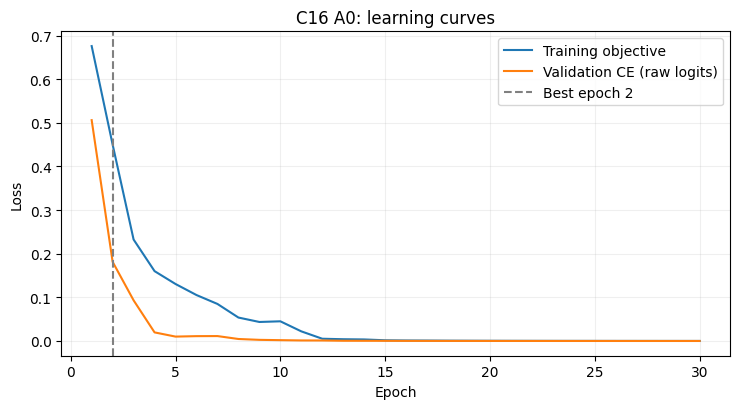

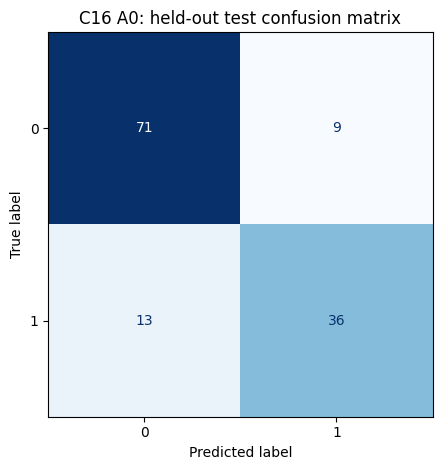

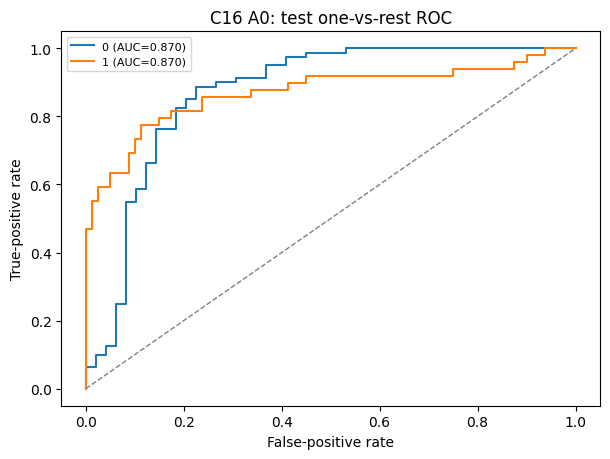

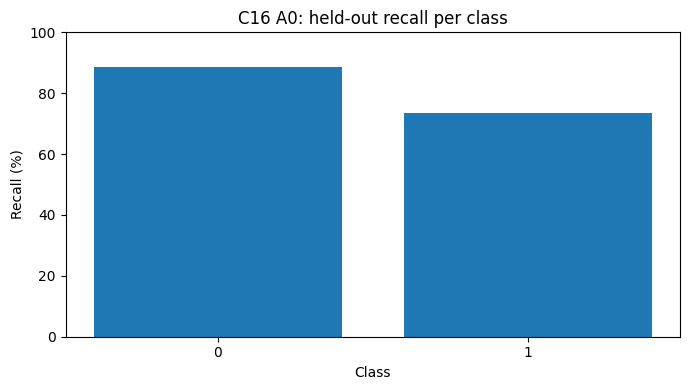

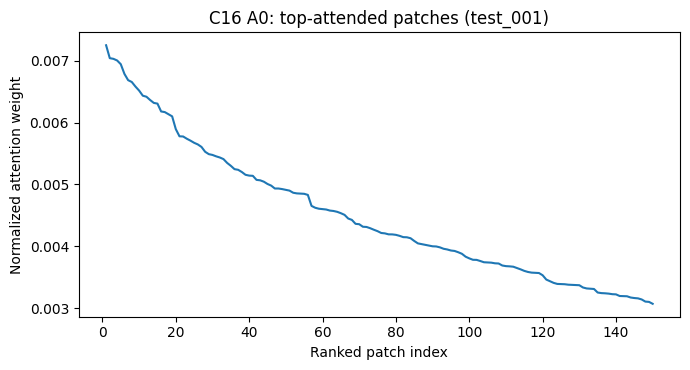

A0: Saved to C:\Users\anest\Desktop\UofT\Digital Image Processing\Project A\Project_A_Starter_Code\Project_A_Starter_Code\results_C16_A0
              precision    recall  f1-score   support

     Class 0     0.8452    0.8875    0.8659        80
     Class 1     0.8000    0.7347    0.7660        49

    accuracy                         0.8295       129
   macro avg     0.8226    0.8111    0.8159       129
weighted avg     0.8281    0.8295    0.8279       129



In [28]:
### ANESTIS

# A0 — USE THE BASELINE YOU ALREADY TRAINED ABOVE (no A0 reimplementation)
# ADDED A0: Save validation-selected original ABMIL weights, plots and predictions.
# Original `model`, `history`, `best_epoch` and `best_model_state` all come from the starter cells.
model.load_state_dict(best_model_state)
A0_SECONDS = sum(float(h.get('epoch_seconds', 0.0)) for h in history)
all_stage_summaries = {}
all_stage_summaries['A0'] = export_stage(
    'A0', model, history, best_epoch, A0_SECONDS,
    'Original starter notebook ABMIL: DimReduction + AttentionGated(K=1) + Classifier1FC + CE')

In [29]:
# Anestis

# ADDED A1-A4: reuse original evaluate(), original AdamW hyperparameters, original loaders.
# No new external .py files. Training automatically generates results_{DATASET}_{Stage}.
def train_extension(stage, constructor, train_objective, description,
                    use_prototype_loss=False):
    seed_everything(int(conf.seed))  # Fair stage initialization
    net = constructor().to(device)
    opt = torch.optim.AdamW(net.parameters(), lr=conf.lr, weight_decay=conf.wd)
    best_score, selected_epoch, selected_state = -float('inf'), -1, None
    stage_history = []
    total_start = time.perf_counter()
    for ep in range(NUM_EPOCHS):
        ep_start = time.perf_counter()
        net.train()
        total_loss = 0.0; total_correct = 0; n_samples = 0
        for batch in train_loader:
            x = batch['input'].to(device, dtype=torch.float32)
            y = batch['label'].to(device, dtype=torch.long).reshape(-1)
            opt.zero_grad(set_to_none=True)
            if use_prototype_loss:
                # ADDED A3: use true SLIDE label only; never invent patch labels.
                logits, aux = net(x, return_aux=True)
                classification_loss = train_objective(logits, y)
                true_class_bag = aux['class_bag_features'][torch.arange(len(y), device=device), y]
                proto_logits = (F.normalize(true_class_bag, dim=-1)
                                @ F.normalize(net.prototypes, dim=-1).T) / A3_TEMPERATURE
                loss_proto = F.cross_entropy(proto_logits, y)
                loss = classification_loss + A3_LAMBDA * loss_proto
            else:
                logits = net(x)
                loss = train_objective(logits, y)
            loss.backward(); opt.step()
            total_loss += float(loss.item()) * len(y)
            total_correct += int((logits.argmax(-1) == y).sum().item())
            n_samples += len(y)
        # REUSE the starter evaluate() and the SAME raw-logits CE for valid loss.
        validation = evaluate(net, nn.CrossEntropyLoss(), val_loader, device, conf)
        score = float(validation['auc']) + float(validation['f1'])
        if not np.isfinite(score): score = float(validation['f1'])
        if score > best_score:
            best_score, selected_epoch = score, ep
            selected_state = {k: v.detach().cpu().clone() for k,v in net.state_dict().items()}
        row = {'epoch': ep, 'train_loss': total_loss / n_samples,
               'train_acc': 100 * total_correct / n_samples,
               'val_loss': float(validation['loss']),
               'val_acc': float(validation['acc']),
               'val_auc': float(validation['auc']), 'val_f1': float(validation['f1']),
               'epoch_seconds': time.perf_counter() - ep_start}
        stage_history.append(row)
        print(f'{DATASET} {stage} epoch {ep+1:02d}/{NUM_EPOCHS}: '
              f'train_obj={row["train_loss"]:.4f}, '
              f'val_auc={row["val_auc"]:.3f}, val_f1={row["val_f1"]:.3f}, '
              f'time={row["epoch_seconds"]:.1f}s; best={selected_epoch+1}')
    if selected_state is None: raise RuntimeError(f'No valid checkpoint for {stage}')
    net.load_state_dict(selected_state)
    wall = time.perf_counter() - total_start
    summary = export_stage(stage, net, stage_history, selected_epoch, wall, description)
    all_stage_summaries[stage] = summary
    del net, opt
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return summary

C16 A1 epoch 01/30: train_obj=0.6748, val_auc=0.915, val_f1=0.841, time=8.8s; best=1
C16 A1 epoch 02/30: train_obj=0.4528, val_auc=0.994, val_f1=0.921, time=6.0s; best=2
C16 A1 epoch 03/30: train_obj=0.2337, val_auc=1.000, val_f1=1.000, time=5.8s; best=3
C16 A1 epoch 04/30: train_obj=0.1508, val_auc=1.000, val_f1=1.000, time=5.8s; best=3
C16 A1 epoch 05/30: train_obj=0.1040, val_auc=1.000, val_f1=1.000, time=5.5s; best=3
C16 A1 epoch 06/30: train_obj=0.0747, val_auc=1.000, val_f1=1.000, time=5.3s; best=3
C16 A1 epoch 07/30: train_obj=0.0700, val_auc=1.000, val_f1=1.000, time=5.4s; best=3
C16 A1 epoch 08/30: train_obj=0.0308, val_auc=1.000, val_f1=1.000, time=5.3s; best=3
C16 A1 epoch 09/30: train_obj=0.0265, val_auc=1.000, val_f1=1.000, time=5.4s; best=3
C16 A1 epoch 10/30: train_obj=0.0153, val_auc=1.000, val_f1=1.000, time=6.0s; best=3
C16 A1 epoch 11/30: train_obj=0.0053, val_auc=1.000, val_f1=1.000, time=7.3s; best=3
C16 A1 epoch 12/30: train_obj=0.0030, val_auc=1.000, val_f1=1.000

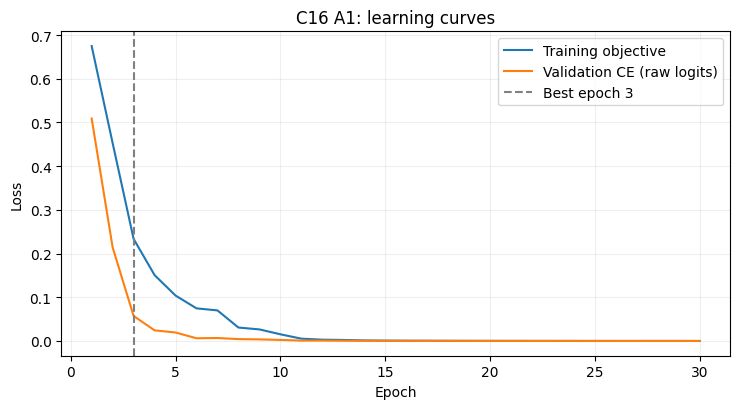

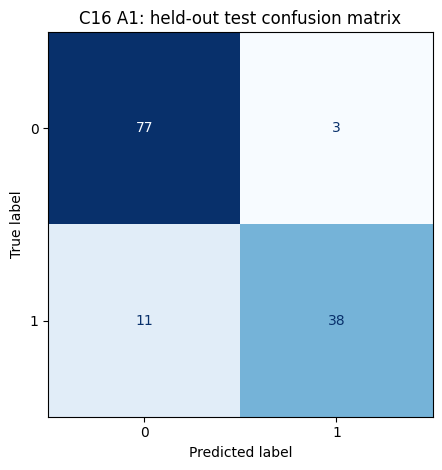

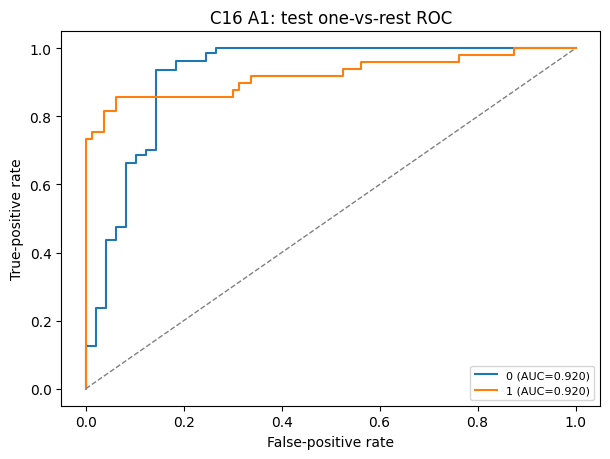

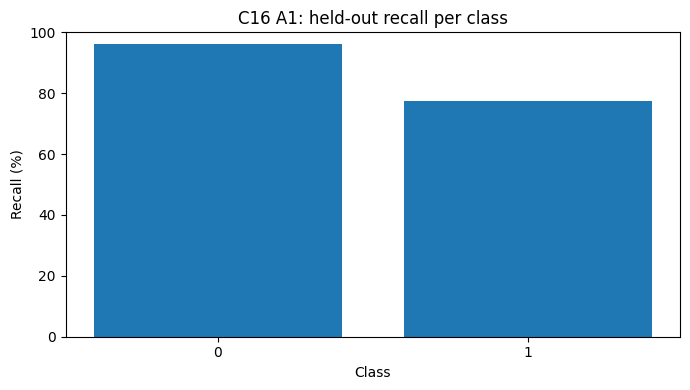

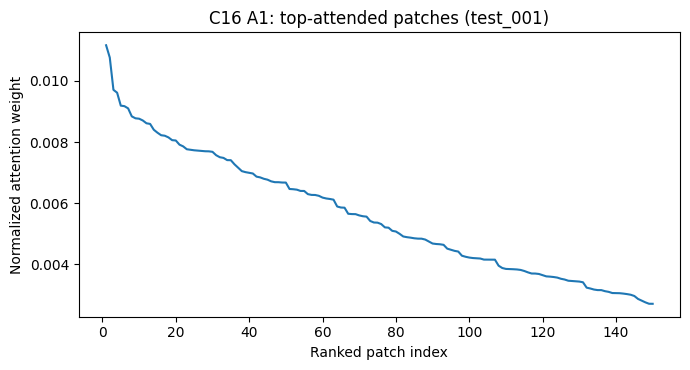

A1: Saved to C:\Users\anest\Desktop\UofT\Digital Image Processing\Project A\Project_A_Starter_Code\Project_A_Starter_Code\results_C16_A1
              precision    recall  f1-score   support

     Class 0     0.8750    0.9625    0.9167        80
     Class 1     0.9268    0.7755    0.8444        49

    accuracy                         0.8915       129
   macro avg     0.9009    0.8690    0.8806       129
weighted avg     0.8947    0.8915    0.8892       129



In [30]:
# Anestis

# ADDED A1: only a training LOSS. Reuses ORIGINAL ABMIL(conf) and ALL its components.
class LogitAdjustedCrossEntropy(nn.Module):
    def __init__(self, counts, tau=0.5):
        super().__init__()
        prior = torch.tensor(counts, dtype=torch.float32)
        prior = prior / prior.sum()
        self.register_buffer('log_prior', prior.log())
        self.tau = float(tau)

    def forward(self, logits, labels):
        # ADDED A1: train-time logit adjustment; do not modify model.forward().
        return F.cross_entropy(logits + self.tau * self.log_prior[None, :], labels)

if 'A1' in RUN_STAGES:
    train_extension(
        'A1', lambda: ABMIL(conf),
        LogitAdjustedCrossEntropy(TRAIN_COUNTS, A1_TAU).to(device),
        'Original ABMIL architecture, only logit-adjusted cross-entropy objective')

C16 A2 epoch 01/30: train_obj=0.6998, val_auc=0.852, val_f1=0.734, time=11.2s; best=1
C16 A2 epoch 02/30: train_obj=0.4424, val_auc=1.000, val_f1=0.961, time=10.0s; best=2
C16 A2 epoch 03/30: train_obj=0.2151, val_auc=1.000, val_f1=1.000, time=9.5s; best=3
C16 A2 epoch 04/30: train_obj=0.1624, val_auc=1.000, val_f1=1.000, time=10.8s; best=3
C16 A2 epoch 05/30: train_obj=0.1187, val_auc=1.000, val_f1=1.000, time=10.4s; best=3
C16 A2 epoch 06/30: train_obj=0.1011, val_auc=1.000, val_f1=1.000, time=9.8s; best=3
C16 A2 epoch 07/30: train_obj=0.0455, val_auc=1.000, val_f1=1.000, time=10.1s; best=3
C16 A2 epoch 08/30: train_obj=0.0377, val_auc=1.000, val_f1=1.000, time=10.2s; best=3
C16 A2 epoch 09/30: train_obj=0.0320, val_auc=1.000, val_f1=1.000, time=10.0s; best=3
C16 A2 epoch 10/30: train_obj=0.0136, val_auc=1.000, val_f1=1.000, time=10.9s; best=3
C16 A2 epoch 11/30: train_obj=0.0053, val_auc=1.000, val_f1=1.000, time=10.3s; best=3
C16 A2 epoch 12/30: train_obj=0.0035, val_auc=1.000, val

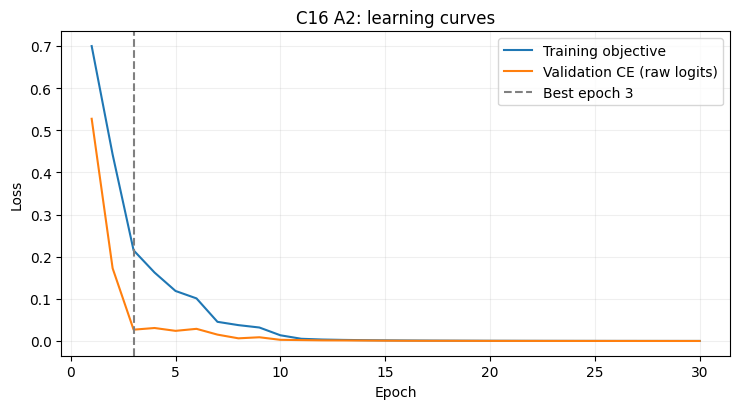

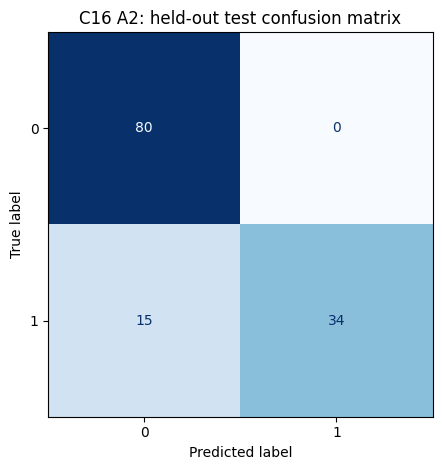

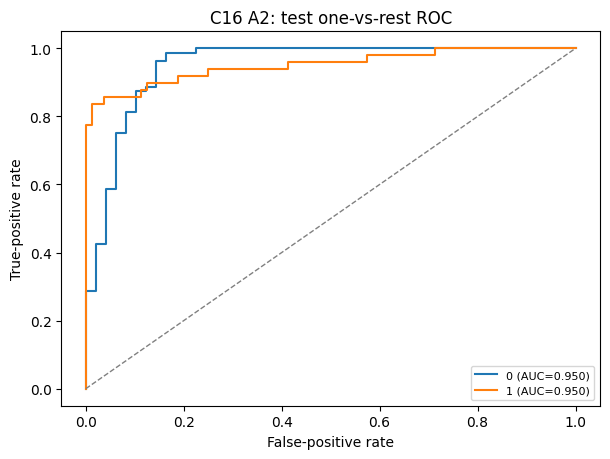

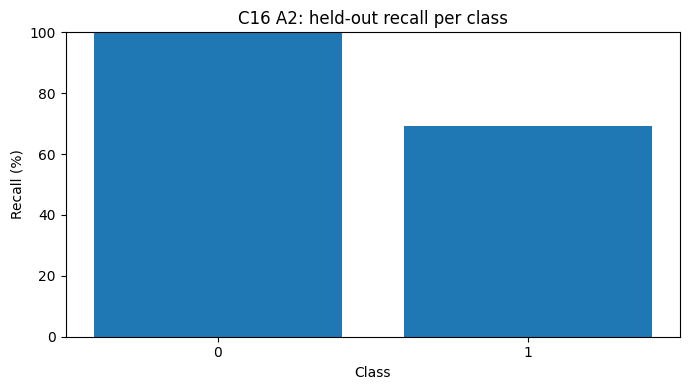

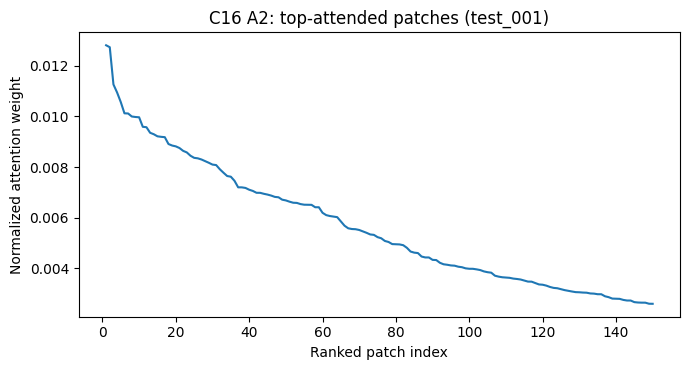

A2: Saved to C:\Users\anest\Desktop\UofT\Digital Image Processing\Project A\Project_A_Starter_Code\Project_A_Starter_Code\results_C16_A2
              precision    recall  f1-score   support

     Class 0     0.8421    1.0000    0.9143        80
     Class 1     1.0000    0.6939    0.8193        49

    accuracy                         0.8837       129
   macro avg     0.9211    0.8469    0.8668       129
weighted avg     0.9021    0.8837    0.8782       129



In [31]:
# ADDED A2: subclass the ORIGINAL ABMIL; original encoder and classifier are REUSED.
class ClassPrototypeABMIL(ABMIL):
    def __init__(self, conf, gamma=1.0):
        super().__init__(conf)  # REUSE original DimReduction, AttentionGated, Classifier1FC
        self.num_classes = int(conf.n_class)
        self.gamma = float(gamma)
        # ADDED A2: class-conditioned gated attention; same original implementation, K=C.
        self.attention = AttentionGated(conf.D_inner, conf.D_attn, K=self.num_classes)
        # ADDED A2: learnable diagnostic prototypes (latent vectors, not patch labels).
        self.prototypes = nn.Parameter(torch.randn(self.num_classes, conf.D_inner) * 0.05)

    def evidence_scores(self, x):
        h = self.dimreduction(x)        # REUSE A0 DimReduction -> [B,N,D_inner]
        gated = self.attention(h)       # REUSE A0 AttentionGated -> [B,C,N]
        patch_unit = F.normalize(h, dim=-1)
        proto_unit = F.normalize(self.prototypes, dim=-1)
        cosine = (patch_unit @ proto_unit.T).transpose(1, 2)  # [B,C,N]
        scores = gated + self.gamma * cosine  # ADDED A2 prototype evidence
        return h, scores

    def forward(self, x, return_attention=False, return_aux=False):
        h, scores = self.evidence_scores(x)
        attention = scores.softmax(dim=-1)  # [B,C,N], normalize over PATCHES
        class_bag_features = torch.bmm(attention, h)  # [B,C,D_inner]
        # REUSE A0 Classifier1FC, applied independently to C class-specific summaries.
        all_class_logits = self.classifier(class_bag_features)  # [B,C,C]
        logits = all_class_logits.diagonal(dim1=1, dim2=2)     # [B,C]
        # ADDED A3 interface: auxiliary output is optional and ignored in A2.
        auxiliary = {'class_bag_features': class_bag_features}
        if return_attention and return_aux: return logits, attention, auxiliary
        if return_attention: return logits, attention
        if return_aux: return logits, auxiliary
        return logits

if 'A2' in RUN_STAGES:
    train_extension(
        'A2', lambda: ClassPrototypeABMIL(conf, gamma=A2_GAMMA),
        LogitAdjustedCrossEntropy(TRAIN_COUNTS, A1_TAU).to(device),
        'A1 loss + class-specific gated attention and one learnable prototype per class')

C16 A3 epoch 01/30: train_obj=0.7336, val_auc=0.847, val_f1=0.734, time=12.2s; best=1
C16 A3 epoch 02/30: train_obj=0.4628, val_auc=1.000, val_f1=0.961, time=9.5s; best=2
C16 A3 epoch 03/30: train_obj=0.2233, val_auc=1.000, val_f1=1.000, time=8.3s; best=3
C16 A3 epoch 04/30: train_obj=0.1704, val_auc=1.000, val_f1=1.000, time=6.4s; best=3
C16 A3 epoch 05/30: train_obj=0.1175, val_auc=1.000, val_f1=1.000, time=7.0s; best=3
C16 A3 epoch 06/30: train_obj=0.0934, val_auc=1.000, val_f1=1.000, time=6.5s; best=3
C16 A3 epoch 07/30: train_obj=0.0427, val_auc=1.000, val_f1=1.000, time=6.2s; best=3
C16 A3 epoch 08/30: train_obj=0.0291, val_auc=1.000, val_f1=1.000, time=6.3s; best=3
C16 A3 epoch 09/30: train_obj=0.0291, val_auc=1.000, val_f1=1.000, time=6.4s; best=3
C16 A3 epoch 10/30: train_obj=0.0321, val_auc=1.000, val_f1=1.000, time=6.4s; best=3
C16 A3 epoch 11/30: train_obj=0.0075, val_auc=1.000, val_f1=1.000, time=6.2s; best=3
C16 A3 epoch 12/30: train_obj=0.0052, val_auc=1.000, val_f1=1.00

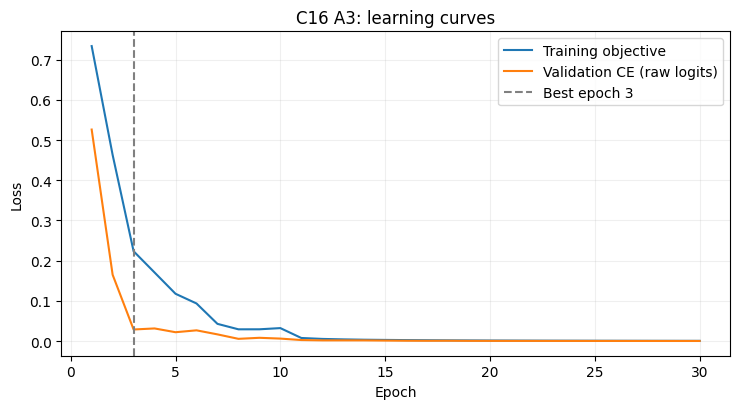

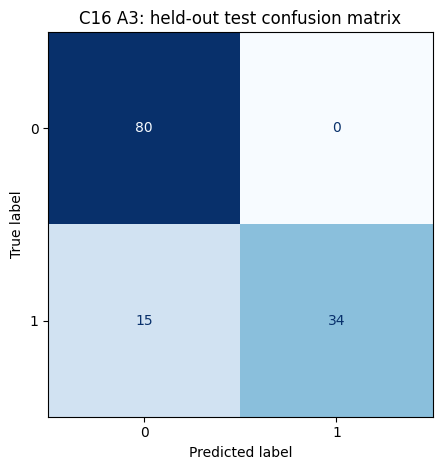

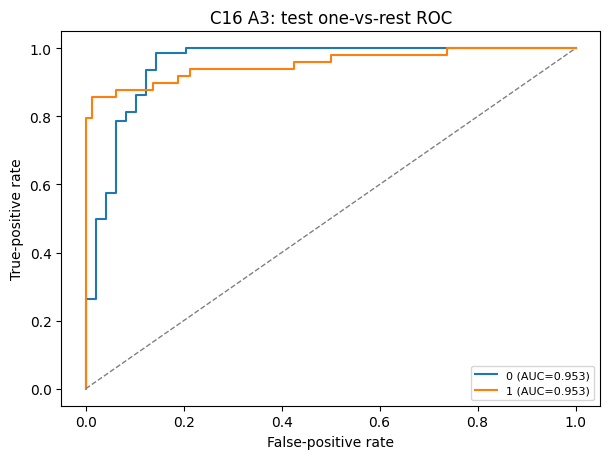

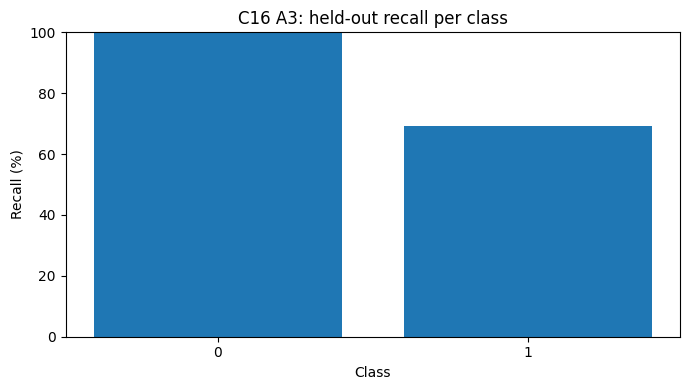

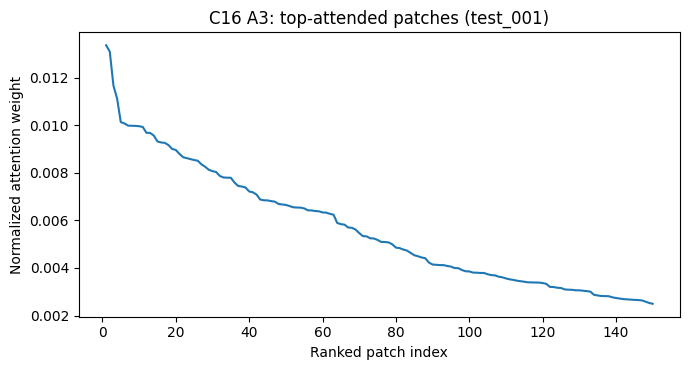

A3: Saved to C:\Users\anest\Desktop\UofT\Digital Image Processing\Project A\Project_A_Starter_Code\Project_A_Starter_Code\results_C16_A3
              precision    recall  f1-score   support

     Class 0     0.8421    1.0000    0.9143        80
     Class 1     1.0000    0.6939    0.8193        49

    accuracy                         0.8837       129
   macro avg     0.9211    0.8469    0.8668       129
weighted avg     0.9021    0.8837    0.8782       129



In [32]:
# ADDED A3: same A2 model; ONLY the auxiliary loss is new.
# The implementation lives in train_extension(..., use_prototype_loss=True) above.
# Extra gradient term: CE(cos(z_y, p_all)/temperature, slide_label).
if 'A3' in RUN_STAGES:
    train_extension(
        'A3', lambda: ClassPrototypeABMIL(conf, gamma=A2_GAMMA),
        LogitAdjustedCrossEntropy(TRAIN_COUNTS, A1_TAU).to(device),
        'A2 model + slide-level supervised prototype discrimination regularizer',
        use_prototype_loss=True)

C16 A4 epoch 01/30: train_obj=0.6461, val_auc=1.000, val_f1=1.000, time=12.7s; best=1
C16 A4 epoch 02/30: train_obj=0.2376, val_auc=1.000, val_f1=1.000, time=10.3s; best=1
C16 A4 epoch 03/30: train_obj=0.1248, val_auc=1.000, val_f1=1.000, time=10.5s; best=1
C16 A4 epoch 04/30: train_obj=0.0885, val_auc=1.000, val_f1=1.000, time=10.3s; best=1
C16 A4 epoch 05/30: train_obj=0.0346, val_auc=1.000, val_f1=1.000, time=10.0s; best=1
C16 A4 epoch 06/30: train_obj=0.0149, val_auc=1.000, val_f1=1.000, time=9.8s; best=1
C16 A4 epoch 07/30: train_obj=0.0033, val_auc=1.000, val_f1=1.000, time=10.3s; best=1
C16 A4 epoch 08/30: train_obj=0.0016, val_auc=1.000, val_f1=1.000, time=10.0s; best=1
C16 A4 epoch 09/30: train_obj=0.0011, val_auc=1.000, val_f1=1.000, time=9.7s; best=1
C16 A4 epoch 10/30: train_obj=0.0009, val_auc=1.000, val_f1=1.000, time=9.8s; best=1
C16 A4 epoch 11/30: train_obj=0.0007, val_auc=1.000, val_f1=1.000, time=10.0s; best=1
C16 A4 epoch 12/30: train_obj=0.0005, val_auc=1.000, val_

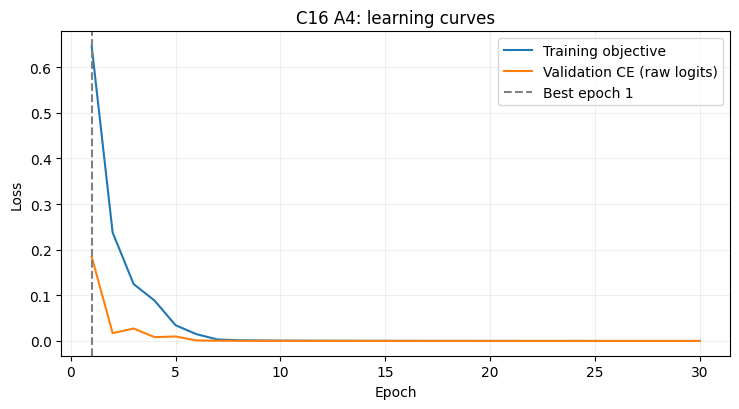

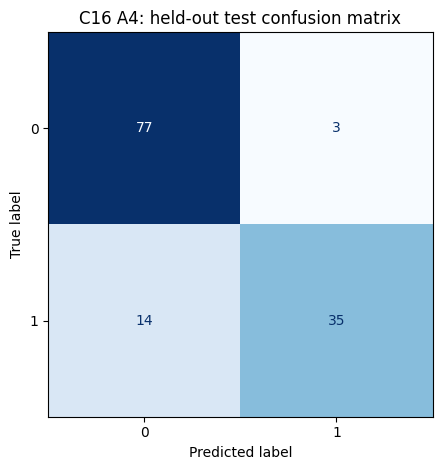

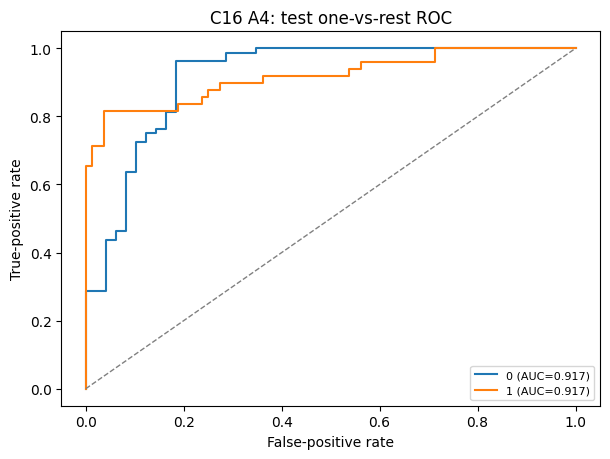

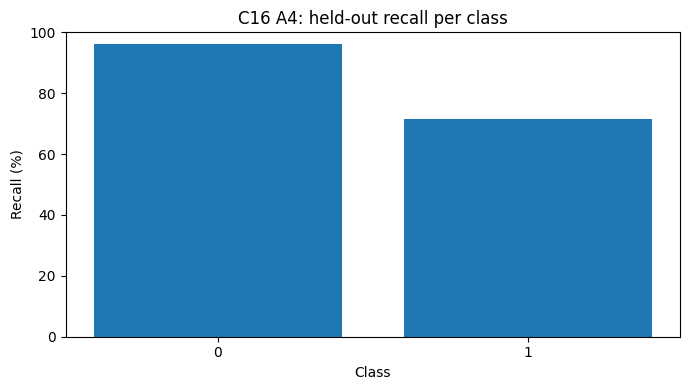

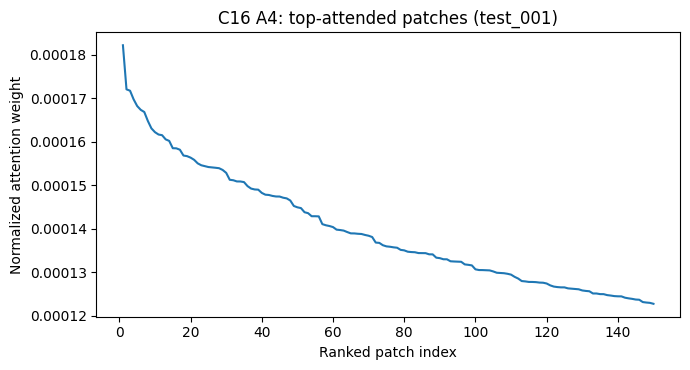

A4: Saved to C:\Users\anest\Desktop\UofT\Digital Image Processing\Project A\Project_A_Starter_Code\Project_A_Starter_Code\results_C16_A4
              precision    recall  f1-score   support

     Class 0     0.8462    0.9625    0.9006        80
     Class 1     0.9211    0.7143    0.8046        49

    accuracy                         0.8682       129
   macro avg     0.8836    0.8384    0.8526       129
weighted avg     0.8746    0.8682    0.8641       129



In [33]:
# ADDED A4: minimal subclass of A2. A0 DimReduction, AttentionGated and Classifier1FC
# remain unchanged. Selected-token MHA adds optional context on top of A2 pooling.
class ContextualClassPrototypeABMIL(ClassPrototypeABMIL):
    def __init__(self, conf, gamma=1.0, top_k=16, heads=4, residual_scale=0.2):
        super().__init__(conf, gamma=gamma)  # REUSE ALL A2 components
        if conf.D_inner % heads != 0:
            raise ValueError('D_inner must be divisible by attention heads')
        self.top_k = int(top_k)
        self.residual_scale = float(residual_scale)
        # ADDED A4: only these modules are new.
        self.context_norm = nn.LayerNorm(conf.D_inner)
        self.context_attention = nn.MultiheadAttention(conf.D_inner, heads, batch_first=True)

    def forward(self, x, return_attention=False, return_aux=False):
        h, scores = self.evidence_scores(x)  # REUSE A2 projected features and scores
        att = scores.softmax(-1)
        z = torch.bmm(att, h)                # REUSE A2 full-bag class pooling
        B, N, D = h.shape
        k = min(self.top_k, N)
        if k < 1: raise ValueError('Empty patch bag')
        # ADDED A4: choose top-k per class; no quadratic N x N attention.
        selected = scores.topk(k, dim=-1).indices.reshape(B, -1)  # [B,C*k]
        chosen = torch.gather(h, 1, selected.unsqueeze(-1).expand(-1, -1, D))
        tokens = self.context_norm(chosen)
        context, _ = self.context_attention(tokens, tokens, tokens, need_weights=False)
        # Re-pool contextual tokens for EACH class using its own original scores.
        selected_scores = torch.gather(
            scores, 2, selected[:, None, :].expand(-1, self.num_classes, -1))
        context_weights = selected_scores.softmax(-1)
        z = z + self.residual_scale * torch.bmm(context_weights, context)
        # REUSE A0 Classifier1FC as in A2; only diagonal class scores are retained.
        all_logits = self.classifier(z)
        logits = all_logits.diagonal(dim1=1, dim2=2)
        auxiliary = {'class_bag_features': z}
        if return_attention and return_aux: return logits, att, auxiliary
        if return_attention: return logits, att
        if return_aux: return logits, auxiliary
        return logits

if 'A4' in RUN_STAGES:
    train_extension(
        'A4', lambda: ContextualClassPrototypeABMIL(
            conf, gamma=A2_GAMMA, top_k=TOP_K_A4, heads=4),
        LogitAdjustedCrossEntropy(TRAIN_COUNTS, A1_TAU).to(device),
        'A3 objective + selected-token four-head contextual attention (not Nystrom)',
        use_prototype_loss=True)

dataset stage  val_accuracy  val_macro_f1  val_macro_ovr_auc  test_accuracy  test_macro_f1  test_macro_ovr_auc  time_minutes  best_epoch
    C16    A0         100.0           1.0                1.0        82.9457         0.8159              0.8704        0.0000           2
    C16    A1         100.0           1.0                1.0        89.1473         0.8806              0.9199        3.4618           3
    C16    A2         100.0           1.0                1.0        88.3721         0.8668              0.9500        4.0792           3
    C16    A3         100.0           1.0                1.0        88.3721         0.8668              0.9531        4.1842           3
    C16    A4         100.0           1.0                1.0        86.8217         0.8526              0.9171        4.6129           1


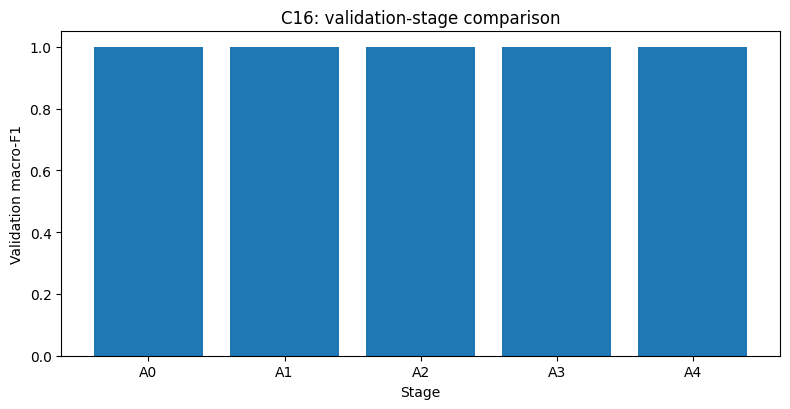

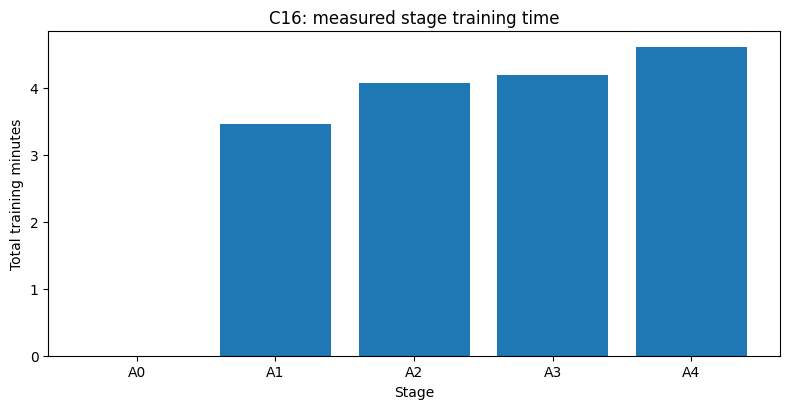

Saved every stage to: C:\Users\anest\Desktop\UofT\Digital Image Processing\Project A\Project_A_Starter_Code\Project_A_Starter_Code
Re-run this entire notebook with the next DATASET (C16, C17 or BRACS).


In [34]:
# ADDED summary: read results actually saved in this run; do not fabricate metrics.
comparison_dir = RESULTS_ROOT / f'results_{DATASET}_comparison'
comparison_dir.mkdir(parents=True, exist_ok=True)
rows = []
for st, sm in all_stage_summaries.items():
    rows.append({'dataset': DATASET, 'stage': st,
                 'val_accuracy': sm['validation']['accuracy'],
                 'val_macro_f1': sm['validation']['macro_f1'],
                 'val_macro_ovr_auc': sm['validation']['macro_ovr_auc'],
                 'test_accuracy': sm['held_out_test']['accuracy'],
                 'test_macro_f1': sm['held_out_test']['macro_f1'],
                 'test_macro_ovr_auc': sm['held_out_test']['macro_ovr_auc'],
                 'time_minutes': sm['wall_seconds'] / 60.0,
                 'best_epoch': sm['best_epoch_1based']})
comparison = pd.DataFrame(rows)
comparison.to_csv(comparison_dir / 'stage_comparison.csv', index=False)
print(comparison.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(comparison['stage'], comparison['val_macro_f1'])
ax.set(xlabel='Stage', ylabel='Validation macro-F1',
       title=f'{DATASET}: validation-stage comparison')
fig.tight_layout(); fig.savefig(comparison_dir / 'validation_macro_f1.png', dpi=180)
plt.show(); plt.close(fig)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(comparison['stage'], comparison['time_minutes'])
ax.set(xlabel='Stage', ylabel='Total training minutes',
       title=f'{DATASET}: measured stage training time')
fig.tight_layout(); fig.savefig(comparison_dir / 'training_minutes.png', dpi=180)
plt.show(); plt.close(fig)
print('Saved every stage to:', RESULTS_ROOT)
print('Re-run this entire notebook with the next DATASET (C16, C17 or BRACS).')

In [35]:
if RUN_OPTIONAL_WSI_HEATMAP and DATASET == 'C16':
    from wsi_visualization import visualize_wsi_attention
    # ORIGINAL optional course visualization, not required for any stage output.
    _ = visualize_wsi_attention(model, conf, PROJECT_DIR, best_model_state)
else:
    print('Optional raw WSI heatmap skipped. Ranked attention and diagnostic plots were saved.')

Optional raw WSI heatmap skipped. Ranked attention and diagnostic plots were saved.
